In [50]:
import itertools

# Isso NÃO carrega os 50 milhões na memória de uma vez
combinacoes = itertools.combinations(range(1, 61), 6)

# Para pegar uma combinação específica pelo índice,
# o ideal é usar lógica matemática em vez de converter para lista.

The `combinacoes` object contains 50 million combinations. Printing all of them directly would consume significant memory and time, potentially crashing the notebook or making it unresponsive. Therefore, I will print only the first few combinations as an example.

In [51]:
# Print the first 5 combinations
print("First 5 combinations:")
for i, combo in enumerate(combinacoes):
    if i >= 5:
        break
    print(combo)

First 5 combinations:
(1, 2, 3, 4, 5, 6)
(1, 2, 3, 4, 5, 7)
(1, 2, 3, 4, 5, 8)
(1, 2, 3, 4, 5, 9)
(1, 2, 3, 4, 5, 10)


In [52]:
import requests
import pandas as pd
import io

# URL do arquivo Excel da Mega-Sena
excel_url = "https://servicebus3.caixa.gov.br/portaldeloterias/api/resultados/download?modalidade=Mega-Sena"

# Faz o download do arquivo
response = requests.get(excel_url)
response.raise_for_status()  # Levanta um erro para status HTTP ruins

# Lê o conteúdo do arquivo em um DataFrame do pandas
df_mega_sena = pd.read_excel(io.BytesIO(response.content))

print("Arquivo Excel baixado e carregado no DataFrame 'df_mega_sena'.")
# Exibe as primeiras 5 linhas do DataFrame para verificação
display(df_mega_sena.head())

Arquivo Excel baixado e carregado no DataFrame 'df_mega_sena'.


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6,Ganhadores 6 acertos,Cidade / UF,Rateio 6 acertos,Ganhadores 5 acertos,Rateio 5 acertos,Ganhadores 4 acertos,Rateio 4 acertos,Acumulado 6 acertos,Arrecadação Total,Estimativa prêmio,Acumulado Sorteio Especial Mega da Virada,Observação
0,1,11/03/1996,4,5,30,33,41,52,0,NaN,"R$0,00",17,"R$39.158,92",2016,"R$330,21","R$1.714.650,23","R$0,00","R$0,00","R$0,00",NaN
1,2,18/03/1996,9,37,39,41,43,49,1,PR,"R$2.307.162,23",65,"R$14.424,02",4488,"R$208,91","R$0,00","R$0,00","R$0,00","R$0,00",NaN
2,3,25/03/1996,10,11,29,30,36,47,2,RN; SP,"R$391.192,51",62,"R$10.515,93",4261,"R$153,01","R$0,00","R$0,00","R$0,00","R$0,00",NaN
3,4,01/04/1996,1,5,6,27,42,59,0,NaN,"R$0,00",39,"R$15.322,24",3311,"R$180,48","R$717.080,75","R$0,00","R$0,00","R$0,00",NaN
4,5,08/04/1996,1,2,6,16,19,46,0,NaN,"R$0,00",98,"R$5.318,10",5399,"R$96,53","R$1.342.488,85","R$0,00","R$0,00","R$0,00",NaN


In [53]:
import pandas as pd
from math import comb

# 1. Identificar as colunas das dezenas (certifique-se que os nomes estão corretos no seu Excel)
# Com base no seu comando, as colunas geralmente são 'Bola1', 'Bola2', etc.
colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

def encontrar_posicao_itertools(linha):
    """
    Calcula a posição exata que uma combinação ocuparia no
    gerador itertools.combinations(range(1, 61), 6)
    """
    # Extrair os números da linha e garantir que estão ordenados
    dezenas = sorted([int(n) for n in linha[colunas_bolas]])

    n = 60
    k = 6
    posicao = 0
    valor_anterior = 1

    for i, valor in enumerate(dezenas):
        # Somamos as combinações que foram "puladas"
        for v in range(valor_anterior, valor):
            posicao += comb(n - v, k - 1 - i)
        valor_anterior = valor + 1

    return posicao + 1

# 2. Criar a nova coluna no DataFrame
print("Calculando o grupo/índice de cada sorteio...")
df_mega_sena['Indice_Combinacao'] = df_mega_sena.apply(encontrar_posicao_itertools, axis=1)

# 3. Exibir o resultado final com a nova coluna
display(df_mega_sena[['Concurso', 'Indice_Combinacao'] + colunas_bolas].head())

Calculando o grupo/índice de cada sorteio...


,Concurso,Indice_Combinacao,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6
0,1,14086154,4,5,30,33,41,52
1,2,32013650,9,37,39,41,43,49
2,3,32230462,10,11,29,30,36,47
3,4,1205764,1,5,6,27,42,59
4,5,93941,1,2,6,16,19,46


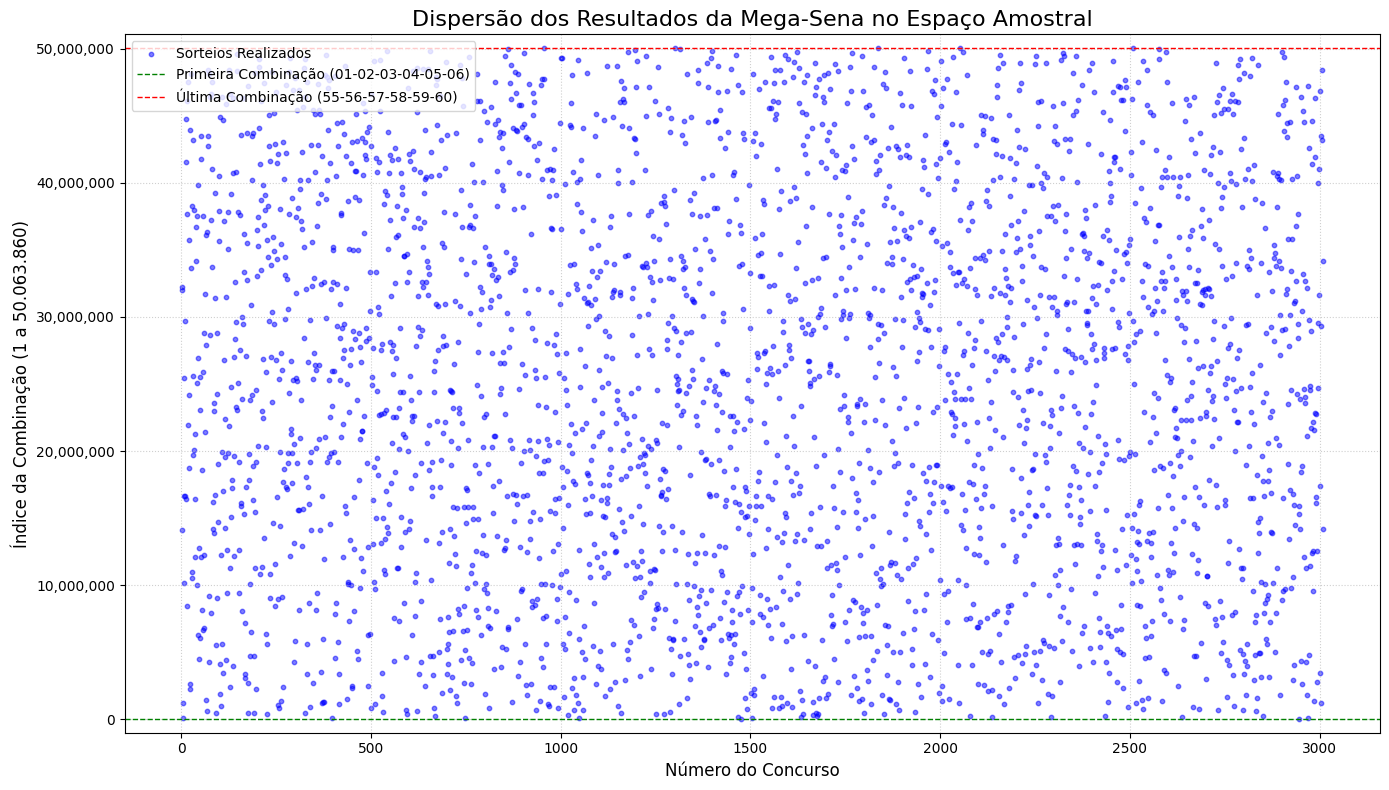

In [54]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Configurações do Gráfico
plt.figure(figsize=(14, 8))

# 2. Plotagem dos dados
# Usamos 's' para o tamanho do ponto e 'alpha' para transparência (ajuda a ver sobreposições)
plt.scatter(df_mega_sena['Concurso'], df_mega_sena['Indice_Combinacao'],
            alpha=0.5, s=10, c='blue', label='Sorteios Realizados')

# 3. Linhas de referência (Limites do Espaço Amostral)
total_combinacoes = 50063860
plt.axhline(y=1, color='green', linestyle='--', linewidth=1, label='Primeira Combinação (01-02-03-04-05-06)')
plt.axhline(y=total_combinacoes, color='red', linestyle='--', linewidth=1, label='Última Combinação (55-56-57-58-59-60)')

# 4. Formatação dos Eixos e Títulos
plt.title('Dispersão dos Resultados da Mega-Sena no Espaço Amostral', fontsize=16)
plt.xlabel('Número do Concurso', fontsize=12)
plt.ylabel('Índice da Combinação (1 a 50.063.860)', fontsize=12)

# Formata o eixo Y para não usar notação científica (ex: 1e7) e colocar separador de milhar
plt.gca().get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# 5. Detalhes Visuais
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.ylim(-1000000, total_combinacoes + 1000000) # Margem para as linhas de limite aparecerem bem

plt.tight_layout()
plt.show()

O índice do jogo [10, 20, 30, 40, 50, 60] é: 33,486,562


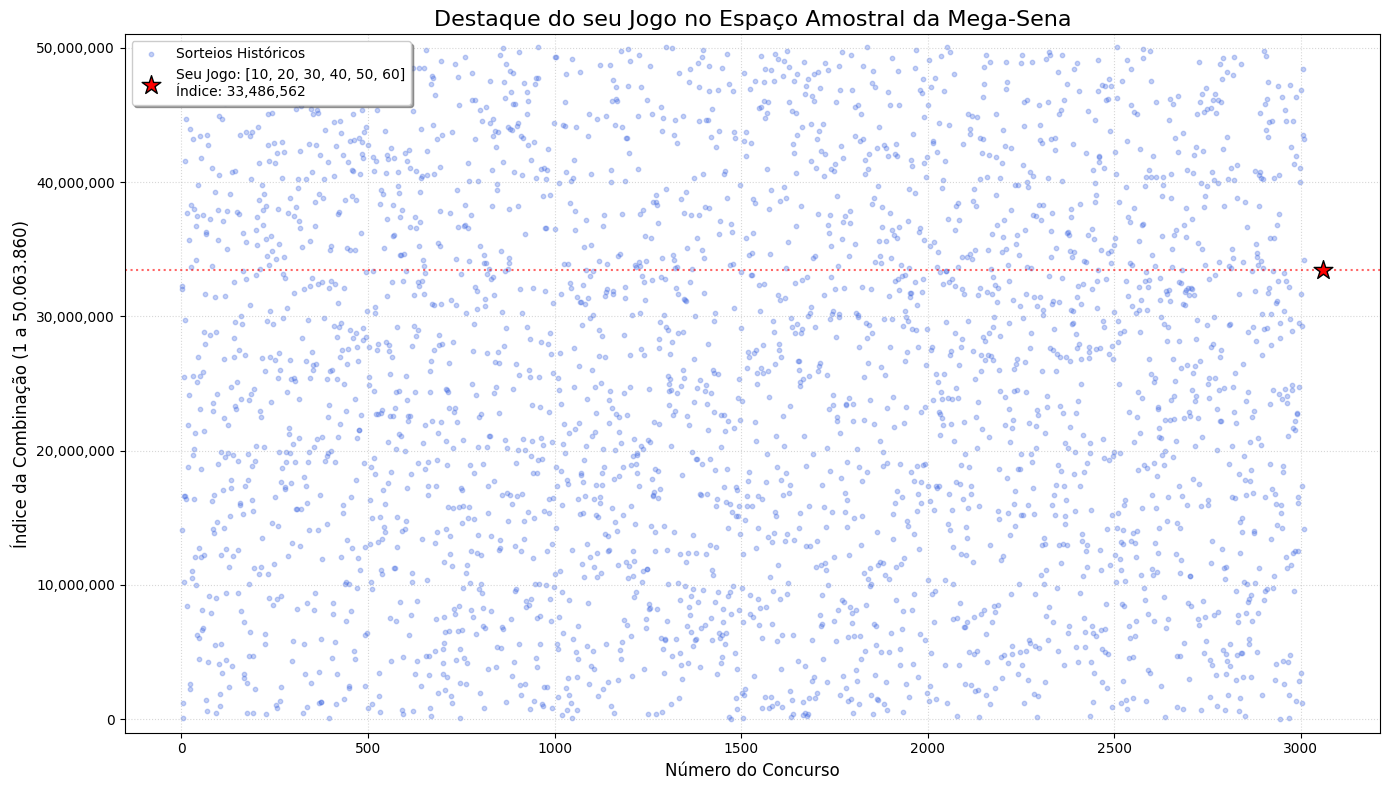

In [55]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- CONFIGURAÇÃO DO SEU JOGO ---
meu_jogo = [10, 20, 30, 40, 50, 60] # <--- COLOQUE SEUS 6 NÚMEROS AQUI
# --------------------------------

def calcular_indice_manual(lista_seis_nums):
    """Calcula o índice de uma lista simples de 6 números"""
    nums = sorted([int(n) for n in lista_seis_nums])
    n, k = 60, 6
    idx = 0
    start = 1
    for i in range(k):
        for v in range(start, nums[i]):
            idx += comb(n - v, k - 1 - i)
        start = nums[i] + 1
    return idx + 1

# 1. Calcula o índice do seu jogo
indice_meu_jogo = calcular_indice_manual(meu_jogo)
print(f"O índice do jogo {meu_jogo} é: {indice_meu_jogo:,}")

# 2. Gerar o Gráfico de Dispersão
plt.figure(figsize=(14, 8))

# Todos os sorteios históricos (em azul claro)
plt.scatter(df_mega_sena['Concurso'], df_mega_sena['Indice_Combinacao'],
            alpha=0.3, s=10, c='royalblue', label='Sorteios Históricos')

# DESTACAR O SEU JOGO (como uma estrela vermelha no "futuro" do gráfico)
ultimo_concurso = df_mega_sena['Concurso'].max()
plt.scatter(ultimo_concurso + 50, indice_meu_jogo,
            color='red', s=200, marker='*', edgecolors='black',
            label=f'Seu Jogo: {meu_jogo}\nÍndice: {indice_meu_jogo:,}', zorder=5)

# Linha horizontal pontilhada para mostrar o nível do seu jogo
plt.axhline(y=indice_meu_jogo, color='red', linestyle=':', alpha=0.6)

# 3. Formatação
plt.title('Destaque do seu Jogo no Espaço Amostral da Mega-Sena', fontsize=16)
plt.xlabel('Número do Concurso', fontsize=12)
plt.ylabel('Índice da Combinação (1 a 50.063.860)', fontsize=12)

plt.gca().get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.ylim(-1000000, 51000000)

plt.tight_layout()
plt.show()

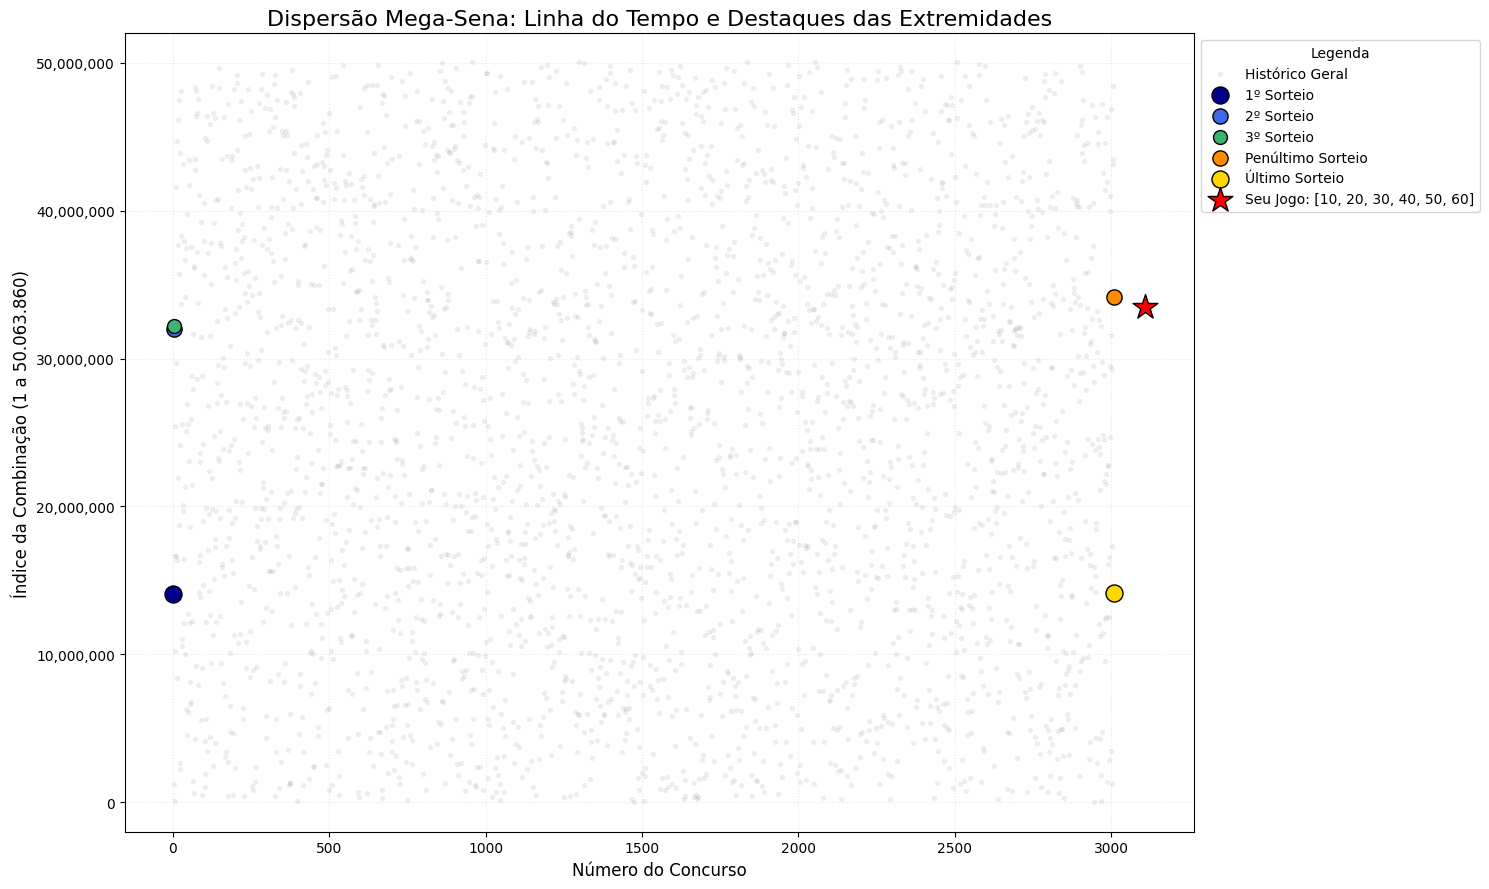

In [56]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from math import comb

# --- CONFIGURAÇÃO DO SEU JOGO ---
meu_jogo = [10, 20, 30, 40, 50, 60]

def calcular_indice_manual(lista_seis_nums):
    nums = sorted([int(n) for n in lista_seis_nums])
    n, k = 60, 6
    idx = 0
    start = 1
    for i in range(k):
        for v in range(start, nums[i]):
            idx += comb(n - v, k - 1 - i)
        start = nums[i] + 1
    return idx + 1

# 1. Identificação dos Pontos Notáveis
indice_meu_jogo = calcular_indice_manual(meu_jogo)
df_ordenado = df_mega_sena.sort_values('Concurso')

# Mapeamento dos sorteios específicos
primeiro = df_ordenado.iloc[0]
segundo  = df_ordenado.iloc[1]
terceiro = df_ordenado.iloc[2]
penultimo = df_ordenado.iloc[-2]
ultimo    = df_ordenado.iloc[-1]

# 2. Gerar o Gráfico
plt.figure(figsize=(15, 9))

# A. Histórico Geral (Cinza bem claro)
plt.scatter(df_mega_sena['Concurso'], df_mega_sena['Indice_Combinacao'],
            alpha=0.1, s=8, c='gray', label='Histórico Geral')

# B. BLOCO DOS PRIMEIROS (Tons de Azul/Verde)
plt.scatter(primeiro['Concurso'], primeiro['Indice_Combinacao'],
            color='darkblue', s=150, edgecolors='black', label='1º Sorteio', zorder=5)
plt.scatter(segundo['Concurso'], segundo['Indice_Combinacao'],
            color='royalblue', s=120, edgecolors='black', label='2º Sorteio', zorder=5)
plt.scatter(terceiro['Concurso'], terceiro['Indice_Combinacao'],
            color='mediumseagreen', s=100, edgecolors='black', label='3º Sorteio', zorder=5)

# C. BLOCO DOS ÚLTIMOS (Tons de Laranja/Ouro)
plt.scatter(penultimo['Concurso'], penultimo['Indice_Combinacao'],
            color='darkorange', s=120, edgecolors='black', label='Penúltimo Sorteio', zorder=5)
plt.scatter(ultimo['Concurso'], ultimo['Indice_Combinacao'],
            color='gold', s=150, edgecolors='black', label='Último Sorteio', zorder=5)

# D. SEU JOGO (Estrela Vermelha)
plt.scatter(ultimo['Concurso'] + 100, indice_meu_jogo,
            color='red', s=350, marker='*', edgecolors='black',
            label=f'Seu Jogo: {meu_jogo}', zorder=6)

# 3. Formatação
plt.title('Dispersão Mega-Sena: Linha do Tempo e Destaques das Extremidades', fontsize=16)
plt.xlabel('Número do Concurso', fontsize=12)
plt.ylabel('Índice da Combinação (1 a 50.063.860)', fontsize=12)

# Formatação do eixo Y
plt.gca().get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.grid(True, linestyle=':', alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title="Legenda", frameon=True) # Legenda fora do gráfico
plt.ylim(-2000000, 52000000)

plt.tight_layout()
plt.show()

Gerando imagem sintética de alta resolução...
Imagem sintética gerada com sucesso: 3000x1669 pixels.


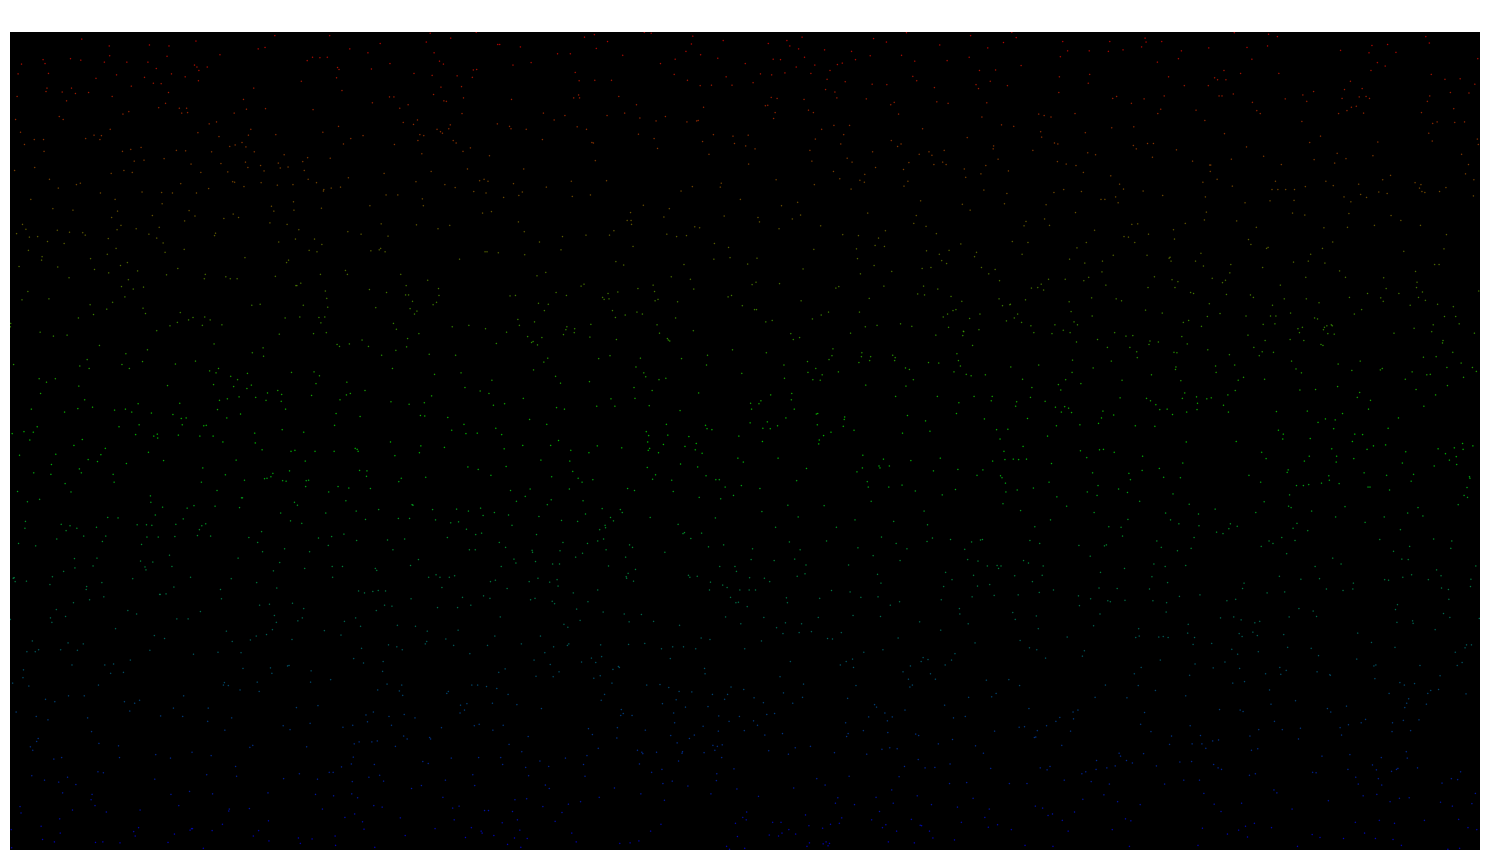

True

In [57]:
import cv2
import numpy as np
import pandas as pd
from math import ceil

# --- 1. CONFIGURAÇÃO DA IMAGEM SINTÉTICA ---
# Como temos 50M de combinações (Y) e ~3000 sorteios (X),
# precisamos de uma imagem de alta resolução para ver os pontos.

TOTAL_COMBINACOES = 50063860
TOTAL_SORTEIOS = df_mega_sena['Concurso'].max()

# Resolução desejada da imagem (Largura x Altura)
# Uma boa resolução para o Colab/Visualização
IMG_W = 3000  # Tempo (Concursos)
IMG_H = 1669  # Espaço Amostral (Combinações)

# Criar a tela em branco (Preto = RGB(0,0,0))
# Usamos 3 canais (RGB)
imagem_sintetica = np.zeros((IMG_H, IMG_W, 3), dtype=np.uint8)

# --- 2. FUNÇÃO DE MAPEAMENTO (Normalização) ---
# Precisamos transformar o Concurso real em X (0 a IMG_W-1)
# E o Índice real em Y (0 a IMG_H-1)

def normalizar_para_pixel(concurso, indice):
    # Eixo X (Tempo): Proporcional
    pixel_x = int((concurso - 1) / TOTAL_SORTEIOS * (IMG_W - 1))

    # Eixo Y (Espaço): Proporcional, invertido (0 é o topo da imagem)
    # Queremos que o índice 1 fique no fundo (IMG_H-1) e 50M no topo (0)
    pixel_y = int((1 - (indice - 1) / TOTAL_COMBINACOES) * (IMG_H - 1))

    # Garantir que não saia dos limites por erro de arredondamento
    pixel_x = max(0, min(pixel_x, IMG_W - 1))
    pixel_y = max(0, min(pixel_y, IMG_H - 1))

    return pixel_x, pixel_y

# --- 3. DEFINIÇÃO DA PALETA DE CORES (OPENCV BGR) ---
# Vamos criar uma paleta que muda de cor conforme a "altura" (Índice Y).
# OpenCV usa BGR (Blue, Green, Red)

def obter_cor_mapeada(indice):
    # Normaliza o índice de 0 a 1
    norm = (indice - 1) / TOTAL_COMBINACOES

    # Exemplo de paleta: Do Azul (Índice Baixo) ao Vermelho (Índice Alto)
    # Passando pelo Verde (Índice Médio)

    blue = int(max(0, 255 * (1 - norm * 2))) if norm < 0.5 else 0
    green = int(255 * (1 - abs(norm - 0.5) * 2))
    red = int(max(0, 255 * (norm * 2 - 1))) if norm > 0.5 else 0

    return (blue, green, red)  # Formato BGR do OpenCV

# --- 4. PROCESSAMENTO E PINTURA DA IMAGEM ---
print("Gerando imagem sintética de alta resolução...")

for _, sorteio in df_mega_sena.iterrows():
    conc = sorteio['Concurso']
    idx = sorteio['Indice_Combinacao']

    # Encontra a coordenada na imagem
    px_x, px_y = normalizar_para_pixel(conc, idx)

    # Encontra a cor baseada no índice
    cor = obter_cor_mapeada(idx)

    # Pinta o pixel. Como é alta resolução, vamos pintar um pequeno
    # círculo para que o ponto seja visível.
    cv2.circle(imagem_sintetica, (px_x, px_y), 1, cor, -1)

# --- 5. EXIBIÇÃO E SALVAMENTO ---
# Como estamos no Colab, precisamos converter BGR para RGB para o Matplotlib exibir corretamente
import matplotlib.pyplot as plt

imagem_rgb = cv2.cvtColor(imagem_sintetica, cv2.COLOR_BGR2RGB)

print(f"Imagem sintética gerada com sucesso: {IMG_W}x{IMG_H} pixels.")

plt.figure(figsize=(15, 10))
plt.imshow(imagem_rgb)
plt.axis('off')  # Esconde eixos e réguas, deixando apenas a imagem pura
plt.title('Imagem Sintética: Dispersão Histórica da Mega-Sena', color='white', fontsize=12)
plt.tight_layout()
plt.show()

# Opcional: Salvar a imagem pura no diretório
cv2.imwrite('mega_sena_sintetica.png', imagem_sintetica)

In [58]:
# Lista das colunas com os números
colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

# Criamos uma versão das dezenas ordenadas para garantir que a comparação seja justa
# (pois 1-2-3-4-5-6 é o mesmo que 6-5-4-3-2-1)
dezenas_ordenadas = df_mega_sena[colunas_bolas].apply(lambda x: sorted(x.values), axis=1)

# Verificando se existem duplicatas
duplicados = dezenas_ordenadas.duplicated()

if duplicados.any():
    print("SURPRESA! Existem sorteios repetidos:")
    display(df_mega_sena[duplicados])
else:
    print("VALIDADO: Nunca houve um sorteio repetido de 6 números na história da Mega-Sena.")

VALIDADO: Nunca houve um sorteio repetido de 6 números na história da Mega-Sena.


In [59]:
from itertools import combinations
import pandas as pd

# 1. Preparar os dados
colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']
mapa_quinas = {}

print("Analisando todas as combinações de 5 números na história...")

# 2. Varrer todos os concursos
for index, row in df_mega_sena.iterrows():
    concurso = int(row['Concurso'])
    # Pegar os 6 números do sorteio e ordenar
    dezenas = sorted([int(row[c]) for c in colunas_bolas])

    # Gerar as 6 combinações possíveis de 5 números dentro desse sorteio
    for quina in combinations(dezenas, 5):
        if quina not in mapa_quinas:
            mapa_quinas[quina] = []
        mapa_quinas[quina].append(concurso)

# 3. Filtrar apenas as que apareceram em mais de um concurso
repeticoes = {quina: concursos for quina, concursos in mapa_quinas.items() if len(concursos) > 1}

# 4. Exibir Resultados e Totais
if repeticoes:
    # Criar o DataFrame de repetidas
    dados_repetidos = []
    for quina, concursos in repeticoes.items():
        dados_repetidos.append({
            'Números da Quina': quina,
            'Concursos': concursos,
            'Vezes': len(concursos)
        })

    df_rep = pd.DataFrame(dados_repetidos).sort_values(by='Vezes', ascending=False)

    # --- CÁLCULO DOS TOTAIS ---
    total_quinas_distintas_repetidas = len(df_rep)
    total_de_ocorrencias_nas_repeticoes = df_rep['Vezes'].sum()

    print("-" * 50)
    print(f"ESTATÍSTICAS DE REPETIÇÃO (QUINA):")
    print(f"Total de conjuntos de 5 números que já se repetiram: {total_quinas_distintas_repetidas}")
    print(f"Total de vezes que essas repetições ocorreram: {total_de_ocorrencias_nas_repeticoes}")
    print("-" * 50)

    display(df_rep.head(10)) # Mostra as 10 mais frequentes
else:
    print("\nNenhuma combinação de 5 números se repetiu até hoje.")

Analisando todas as combinações de 5 números na história...
--------------------------------------------------
ESTATÍSTICAS DE REPETIÇÃO (QUINA):
Total de conjuntos de 5 números que já se repetiram: 25
Total de vezes que essas repetições ocorreram: 50
--------------------------------------------------


,Números da Quina,Concursos,Vezes
0,"(14, 23, 24, 26, 51)","[186, 334]",2
1,"(14, 36, 53, 55, 60)","[220, 2064]",2
2,"(19, 22, 29, 41, 59)","[232, 2108]",2
3,"(2, 16, 37, 43, 57)","[246, 745]",2
4,"(4, 11, 25, 39, 55)","[308, 309]",2
5,"(7, 23, 33, 57, 59)","[335, 2075]",2
6,"(16, 29, 34, 49, 51)","[342, 1639]",2
7,"(4, 22, 28, 30, 49)","[540, 2644]",2
8,"(11, 13, 38, 39, 54)","[586, 812]",2
9,"(11, 21, 30, 35, 52)","[688, 1011]",2


In [60]:
from itertools import combinations
import pandas as pd

# Configuração das colunas do seu DataFrame
colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

def analisar_estatisticas_repeticao(n_numeros):
    mapa_frequencia = {}

    # Percorre cada sorteio do histórico
    for _, linha in df_mega_sena.iterrows():
        dezenas = sorted([int(linha[c]) for c in colunas_bolas])

        # Gera grupos (duplas, ternos, quadras ou quinas)
        for grupo in combinations(dezenas, n_numeros):
            mapa_frequencia[grupo] = mapa_frequencia.get(grupo, 0) + 1

    # Filtra apenas os grupos que apareceram mais de 1 vez
    apenas_repetidos = {k: v for k, v in mapa_frequencia.items() if v > 1}

    return {
        'Tipo de Grupo': f'Grupos de {n_numeros} números',
        'Combinações que se Repetiram': len(apenas_repetidos),
        'Total de Vezes que Reapareceram': sum(apenas_repetidos.values()),
        'Exemplo de Repetição Máxima': max(mapa_frequencia.values()) if mapa_frequencia else 0
    }

# Executar a análise para Quinas, Quadras, Ternos e Duplas
print("Processando análise estatística... Por favor, aguarde.")
resultados_finais = []
for i in [5, 4, 3, 2]:
    resultados_finais.append(analisar_estatisticas_repeticao(i))

# Criar DataFrame com labels explicativas
df_relatorio = pd.DataFrame(resultados_finais)

# Renomear colunas para máxima clareza
df_relatorio.columns = [
    'Análise (Qtd de Números)',
    'Qtd de Conjuntos Diferentes que já se Repetiram',
    'Soma Total de Ocorrências desses Conjuntos',
    'Recorde: Vezes que um mesmo conjunto saiu'
]

print("\n" + "="*80)
print("RELATÓRIO DE REPETIÇÕES HISTÓRICAS NA MEGA-SENA")
print("="*80)
display(df_relatorio)

print("\nNOTAS EXPLICATIVAS:")
print("- 'Qtd de Conjuntos Diferentes': Quantos grupos únicos de números deixaram de ser inéditos.")
print("- 'Soma Total de Ocorrências': O volume total de vezes que esses números premiaram alguém.")
print("- 'Recorde': O máximo de vezes que um mesmo grupo (ex: uma mesma dupla) apareceu na história.")

Processando análise estatística... Por favor, aguarde.

RELATÓRIO DE REPETIÇÕES HISTÓRICAS NA MEGA-SENA


,Análise (Qtd de Números),Qtd de Conjuntos Diferentes que já se Repetiram,Soma Total de Ocorrências desses Conjuntos,Recorde: Vezes que um mesmo conjunto saiu
0,Grupos de 5 números,25,50,2
1,Grupos de 4 números,2023,4116,4
2,Grupos de 3 números,17865,49798,8
3,Grupos de 2 números,1770,45135,41



NOTAS EXPLICATIVAS:
- 'Qtd de Conjuntos Diferentes': Quantos grupos únicos de números deixaram de ser inéditos.
- 'Soma Total de Ocorrências': O volume total de vezes que esses números premiaram alguém.
- 'Recorde': O máximo de vezes que um mesmo grupo (ex: uma mesma dupla) apareceu na história.


Gerando imagem sintética de alta resolução...
Imagem sintética gerada com sucesso: 3000x1669 pixels.


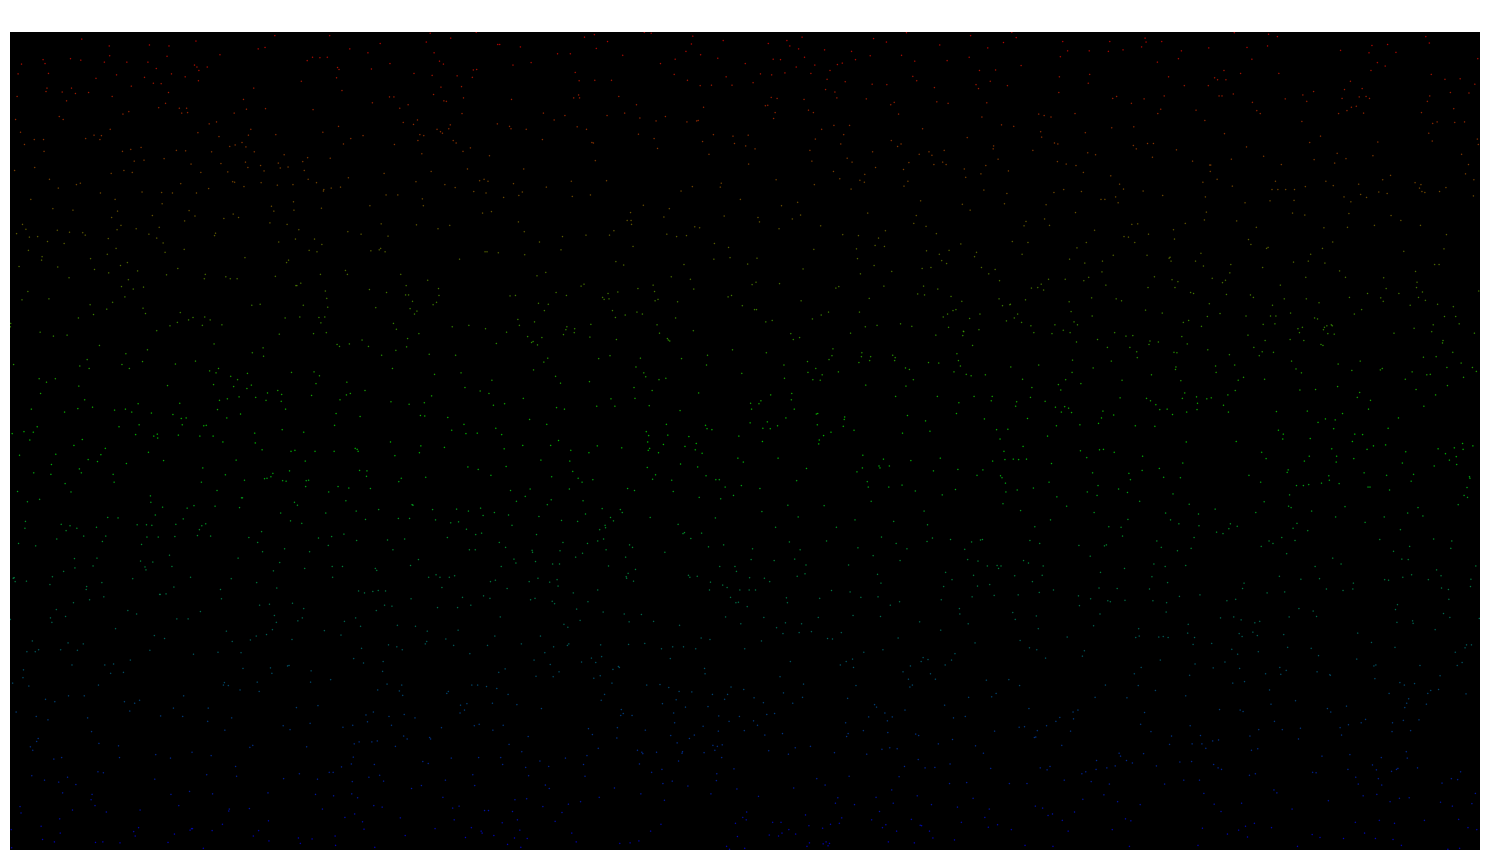

True

In [61]:
import cv2
import numpy as np
import pandas as pd
from math import ceil

# --- 1. CONFIGURAÇÃO DA IMAGEM SINTÉTICA ---
# Como temos 50M de combinações (Y) e ~3000 sorteios (X),
# precisamos de uma imagem de alta resolução para ver os pontos.

TOTAL_COMBINACOES = 50063860
TOTAL_SORTEIOS = df_mega_sena['Concurso'].max()

# Resolução desejada da imagem (Largura x Altura)
# Uma boa resolução para o Colab/Visualização
IMG_W = 3000  # Tempo (Concursos)
IMG_H = 1669  # Espaço Amostral (Combinações)

# Criar a tela em branco (Preto = RGB(0,0,0))
# Usamos 3 canais (RGB)
imagem_sintetica = np.zeros((IMG_H, IMG_W, 3), dtype=np.uint8)

# --- 2. FUNÇÃO DE MAPEAMENTO (Normalização) ---
# Precisamos transformar o Concurso real em X (0 a IMG_W-1)
# E o Índice real em Y (0 a IMG_H-1)

def normalizar_para_pixel(concurso, indice):
    # Eixo X (Tempo): Proporcional
    pixel_x = int((concurso - 1) / TOTAL_SORTEIOS * (IMG_W - 1))

    # Eixo Y (Espaço): Proporcional, invertido (0 é o topo da imagem)
    # Queremos que o índice 1 fique no fundo (IMG_H-1) e 50M no topo (0)
    pixel_y = int((1 - (indice - 1) / TOTAL_COMBINACOES) * (IMG_H - 1))

    # Garantir que não saia dos limites por erro de arredondamento
    pixel_x = max(0, min(pixel_x, IMG_W - 1))
    pixel_y = max(0, min(pixel_y, IMG_H - 1))

    return pixel_x, pixel_y

# --- 3. DEFINIÇÃO DA PALETA DE CORES (OPENCV BGR) ---
# Vamos criar uma paleta que muda de cor conforme a "altura" (Índice Y).
# OpenCV usa BGR (Blue, Green, Red)

def obter_cor_mapeada(indice):
    # Normaliza o índice de 0 a 1
    norm = (indice - 1) / TOTAL_COMBINACOES

    # Exemplo de paleta: Do Azul (Índice Baixo) ao Vermelho (Índice Alto)
    # Passando pelo Verde (Índice Médio)

    blue = int(max(0, 255 * (1 - norm * 2))) if norm < 0.5 else 0
    green = int(255 * (1 - abs(norm - 0.5) * 2))
    red = int(max(0, 255 * (norm * 2 - 1))) if norm > 0.5 else 0

    return (blue, green, red)  # Formato BGR do OpenCV

# --- 4. PROCESSAMENTO E PINTURA DA IMAGEM ---
print("Gerando imagem sintética de alta resolução...")

for _, sorteio in df_mega_sena.iterrows():
    conc = sorteio['Concurso']
    idx = sorteio['Indice_Combinacao']

    # Encontra a coordenada na imagem
    px_x, px_y = normalizar_para_pixel(conc, idx)

    # Encontra a cor baseada no índice
    cor = obter_cor_mapeada(idx)

    # Pinta o pixel. Como é alta resolução, vamos pintar um pequeno
    # círculo para que o ponto seja visível.
    cv2.circle(imagem_sintetica, (px_x, px_y), 1, cor, -1)

# --- 5. EXIBIÇÃO E SALVAMENTO ---
# Como estamos no Colab, precisamos converter BGR para RGB para o Matplotlib exibir corretamente
import matplotlib.pyplot as plt

imagem_rgb = cv2.cvtColor(imagem_sintetica, cv2.COLOR_BGR2RGB)

print(f"Imagem sintética gerada com sucesso: {IMG_W}x{IMG_H} pixels.")

plt.figure(figsize=(15, 10))
plt.imshow(imagem_rgb)
plt.axis('off')  # Esconde eixos e réguas, deixando apenas a imagem pura
plt.title('Imagem Sintética: Dispersão Histórica da Mega-Sena', color='white', fontsize=12)
plt.tight_layout()
plt.show()

# Opcional: Salvar a imagem pura no diretório
cv2.imwrite('mega_sena_sintetica.png', imagem_sintetica)

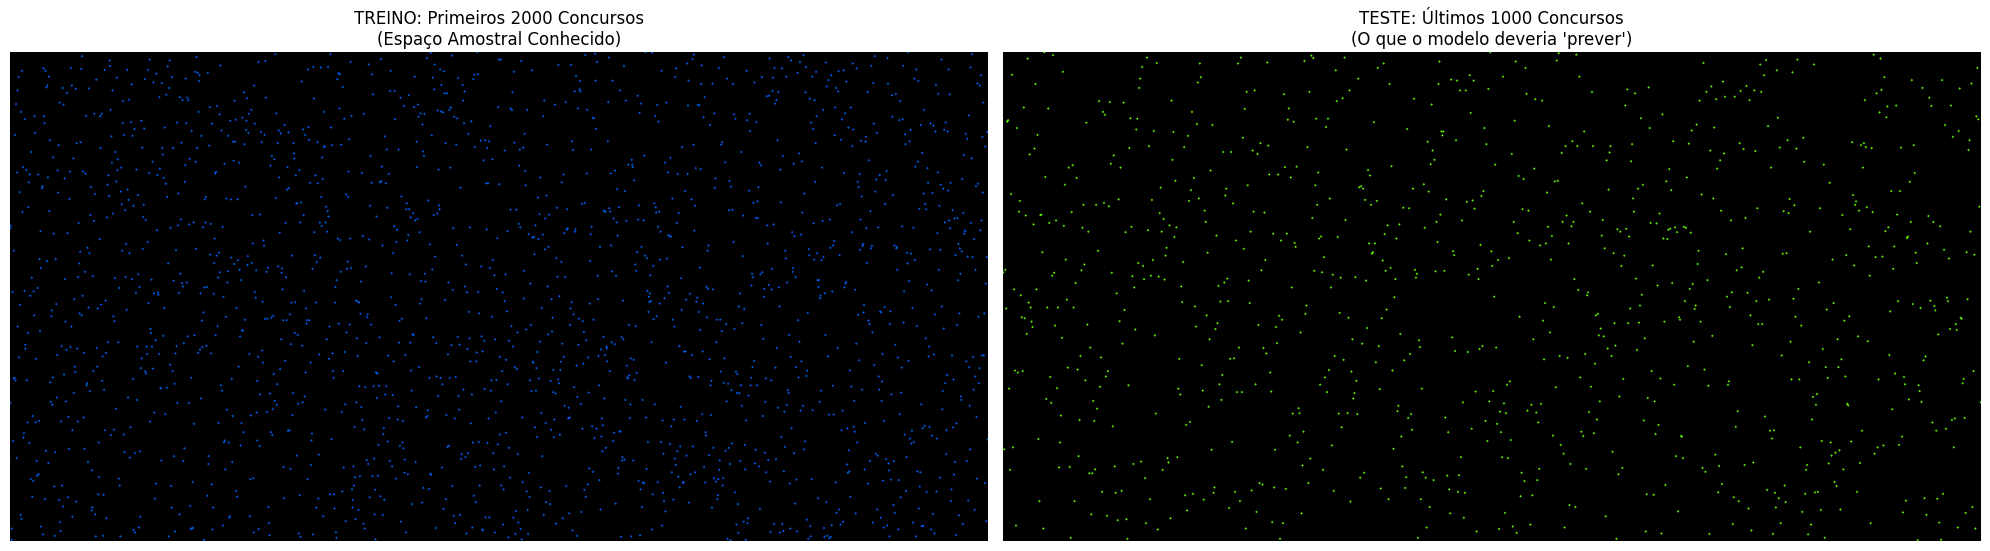

--------------------------------------------------
RESULTADO DA VALIDAÇÃO:
Combinações de 6 números repetidas entre os dois períodos: 0
Conclusão: Nenhuma Sena se repetiu. O 'Treino' não previu o 'Teste'.


In [62]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. DIVISÃO DOS DADOS (TREINO E TESTE)
df_ordenado = df_mega_sena.sort_values('Concurso')
df_treino = df_ordenado.head(2000)
df_teste = df_ordenado.tail(1000)

# 2. CONFIGURAÇÃO DA IMAGEM
IMG_W, IMG_H = 2000, 1000
TOTAL_COMB = 50063860

def criar_imagem_sintetica(df, titulo_cor):
    # Criar tela preta
    img = np.zeros((IMG_H, IMG_W, 3), dtype=np.uint8)

    # Normalização
    min_conc = df['Concurso'].min()
    max_conc = df['Concurso'].max()
    intervalo_conc = max_conc - min_conc if max_conc != min_conc else 1

    for _, row in df.iterrows():
        # Calcular X (tempo relativo ao bloco) e Y (índice da combinação)
        x = int(((row['Concurso'] - min_conc) / intervalo_conc) * (IMG_W - 1))
        y = int((1 - (row['Indice_Combinacao'] / TOTAL_COMB)) * (IMG_H - 1))

        # Cor baseada na posição (Azul para Treino, Verde para Teste)
        cor = (255, 100, 0) if titulo_cor == "Treino" else (0, 255, 100) # BGR
        cv2.circle(img, (x, y), 2, cor, -1)

    return img

# Gerar as duas imagens
img_treino = criar_imagem_sintetica(df_treino, "Treino")
img_teste = criar_imagem_sintetica(df_teste, "Teste")

# 3. EXIBIÇÃO LADO A LADO
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].imshow(cv2.cvtColor(img_treino, cv2.COLOR_BGR2RGB))
ax[0].set_title(f"TREINO: Primeiros 2000 Concursos\n(Espaço Amostral Conhecido)")
ax[0].axis('off')

ax[1].imshow(cv2.cvtColor(img_teste, cv2.COLOR_BGR2RGB))
ax[1].set_title(f"TESTE: Últimos 1000 Concursos\n(O que o modelo deveria 'prever')")
ax[1].axis('off')

plt.tight_layout()
plt.show()

# 4. VALIDAÇÃO MATEMÁTICA: "EU ACERTARIA?"
# Vamos checar se algum índice do conjunto de TESTE já apareceu no TREINO
indices_treino = set(df_treino['Indice_Combinacao'])
indices_teste = set(df_teste['Indice_Combinacao'])

interseccao = indices_treino.intersection(indices_teste)

print("-" * 50)
print(f"RESULTADO DA VALIDAÇÃO:")
print(f"Combinações de 6 números repetidas entre os dois períodos: {len(interseccao)}")
if len(interseccao) == 0:
    print("Conclusão: Nenhuma Sena se repetiu. O 'Treino' não previu o 'Teste'.")
else:
    print(f"Conclusão: Incrível! Os concursos {interseccao} se repetiram.")

In [63]:
from itertools import combinations

# 1. Separar os dados
df_treino = df_mega_sena.sort_values('Concurso').head(2000)
df_teste = df_mega_sena.sort_values('Concurso').tail(1000)

colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

def extrair_conjuntos(df, n_elementos):
    """Extrai todos os conjuntos únicos de N números que apareceram no DF"""
    conjuntos = set()
    for _, row in df.iterrows():
        dezenas = sorted([int(row[c]) for c in colunas_bolas])
        for combo in combinations(dezenas, n_elementos):
            conjuntos.add(combo)
    return conjuntos

# 2. Gerar base de 'conhecimento' do Treino (o que você 'apostaria')
print("Mapeando padrões do conjunto de Treino (2000 concursos)...")
senas_treino = extrair_conjuntos(df_treino, 6)
quinas_treino = extrair_conjuntos(df_treino, 5)
quadras_treino = extrair_conjuntos(df_treino, 4)

# 3. Comparar com o Teste (o que realmente aconteceu)
print("Comparando com o conjunto de Teste (1000 concursos)...")
acertos_sena = 0
acertos_quina = 0
acertos_quadra = 0

for _, row in df_teste.iterrows():
    dezenas_teste = sorted([int(row[c]) for c in colunas_bolas])

    # Conferindo Sena
    if tuple(dezenas_teste) in senas_treino:
        acertos_sena += 1

    # Conferindo Quinas dentro desse sorteio
    for q in combinations(dezenas_teste, 5):
        if q in quinas_treino:
            acertos_quina += 1
            break # Conta apenas uma quina por concurso para o relatório

    # Conferindo Quadras dentro desse sorteio
    for qd in combinations(dezenas_teste, 4):
        if qd in quadras_treino:
            acertos_quadra += 1
            break # Conta apenas uma quadra por concurso para o relatório

# 4. Exibir Relatório de Performance
print("\n" + "="*40)
print("RELATÓRIO DE ACERTOS (BACKTESTING)")
print(f"Base de Treino: 2000 sorteios")
print(f"Base de Teste:  1000 sorteios")
print("="*40)
print(f"Acertos de SENA:   {acertos_sena} (Repetições de 6 números)")
print(f"Acertos de QUINA:  {acertos_quina} (Concursos de teste que tinham 5 números do treino)")
print(f"Acertos de QUADRA: {acertos_quadra} (Concursos de teste que tinham 4 números do treino)")
print("-" * 40)
print(f"Percentual de sucesso (Quadra): {(acertos_quadra/1000)*100:.2f}%")

Mapeando padrões do conjunto de Treino (2000 concursos)...
Comparando com o conjunto de Teste (1000 concursos)...

RELATÓRIO DE ACERTOS (BACKTESTING)
Base de Treino: 2000 sorteios
Base de Teste:  1000 sorteios
Acertos de SENA:   0 (Repetições de 6 números)
Acertos de QUINA:  12 (Concursos de teste que tinham 5 números do treino)
Acertos de QUADRA: 573 (Concursos de teste que tinham 4 números do treino)
----------------------------------------
Percentual de sucesso (Quadra): 57.30%


Treinando a rede neural... isso pode levar um minuto.
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - loss: 0.1041 - val_loss: 0.0786
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0873 - val_loss: 0.0772
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0871 - val_loss: 0.0770
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0865 - val_loss: 0.0767
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0856 - val_loss: 0.0767
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0850 - val_loss: 0.0769
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0843 - val_loss: 0.0803
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0849 - val_loss: 0.0768
Epoch 9/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0833 - val_loss: 0.0768
Epoch 10/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0842 - val_loss: 0.0769
Epoch 11/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0845 - val_loss: 0.0767
Epoch 12/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0839 - val_l

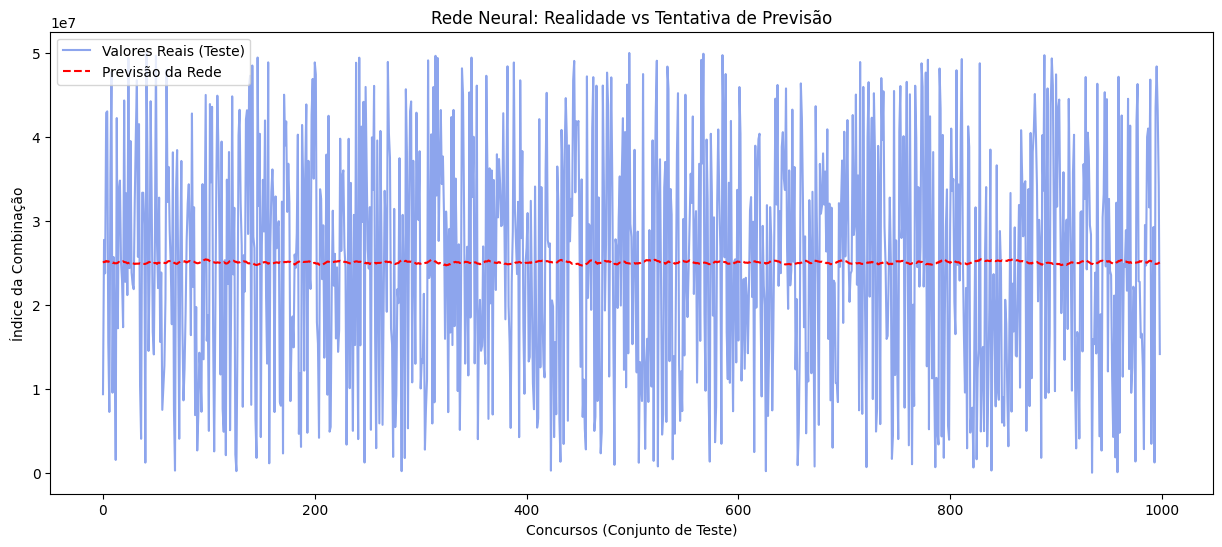

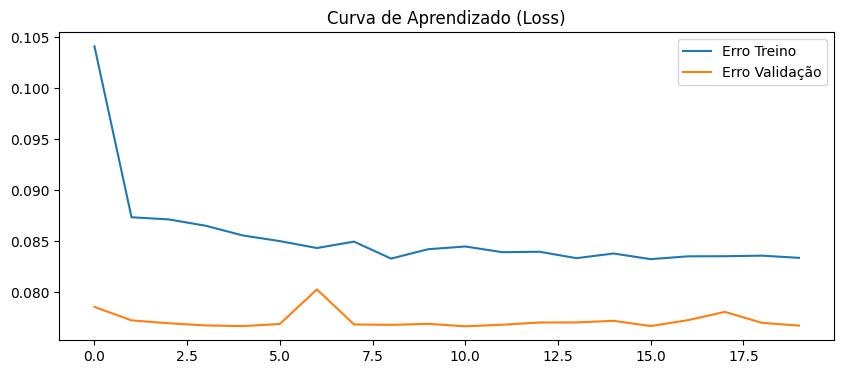

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1. Preparação dos Dados
# Vamos usar a coluna 'Indice_Combinacao' que criamos
dados = df_mega_sena['Indice_Combinacao'].values.reshape(-1, 1)

# Normalização (Redes neurais trabalham melhor com valores entre 0 e 1)
scaler = MinMaxScaler(feature_range=(0, 1))
dados_norm = scaler.fit_transform(dados)

# Criar janelas de tempo (Lookback)
# Usaremos os últimos 10 concursos para prever o próximo
def criar_janelas(data, window_size=10):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size, 0])
        y.append(data[i + window_size, 0])
    return np.array(X), np.array(y)

window_size = 10
X, y = criar_janelas(dados_norm, window_size)

# Divisão Treino (2000) e Teste (restante)
X_train, X_test = X[:2000], X[2000:]
y_train, y_test = y[:2000], y[2000:]

# Reshape para o formato do LSTM: [amostras, janelas, recursos]
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

# 2. Construção da Rede Neural (LSTM)
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(window_size, 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

# 3. Treinamento
print("Treinando a rede neural... isso pode levar um minuto.")
history = model.fit(X_train, y_train, batch_size=32, epochs=20,
                    validation_data=(X_test, y_test), verbose=1)

# 4. Previsão e Visualização
previsoes = model.predict(X_test)
previsoes = scaler.inverse_transform(previsoes) # Volta para a escala de 1 a 50M
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

# 5. Gráfico de Resultado
plt.figure(figsize=(15, 6))
plt.plot(y_test_real, label='Valores Reais (Teste)', color='royalblue', alpha=0.6)
plt.plot(previsoes, label='Previsão da Rede', color='red', linestyle='--')
plt.title('Rede Neural: Realidade vs Tentativa de Previsão')
plt.xlabel('Concursos (Conjunto de Teste)')
plt.ylabel('Índice da Combinação')
plt.legend()
plt.show()

# Gráfico de Perda (Loss)
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Erro Treino')
plt.plot(history.history['val_loss'], label='Erro Validação')
plt.title('Curva de Aprendizado (Loss)')
plt.legend()
plt.show()

In [65]:
# 1. Pegar os últimos 'window_size' concursos do DataFrame original
ultimos_10_indices = df_mega_sena['Indice_Combinacao'].tail(window_size).values.reshape(-1, 1)

# 2. Normalizar esses dados com o mesmo scaler usado no treino
ultimos_10_norm = scaler.transform(ultimos_10_indices)

# 3. Preparar o formato para a Rede Neural (1 amostra, 10 janelas, 1 recurso)
entrada_predict = np.reshape(ultimos_10_norm, (1, window_size, 1))

# 4. Realizar a Previsão
predicao_norm = model.predict(entrada_predict)

# 5. Desnormalizar para obter o Índice de 1 a 50M
indice_previsto = int(scaler.inverse_transform(predicao_norm)[0][0])

# --- FUNÇÃO PARA CONVERTER ÍNDICE EM 6 NÚMEROS ---
def indice_para_combinacao(index, n=60, k=6):
    """Converte um índice (1-50.063.860) de volta para os 6 números"""
    combinacao = []
    current = 1
    for i in range(k):
        while True:
            c = comb(n - current, k - 1 - i)
            if index <= c:
                combinacao.append(current)
                break
            index -= c
            current += 1
        current += 1
    return combinacao

# 6. Resultado Final
jogo_previsto = indice_para_combinacao(indice_previsto)

print("-" * 40)
print(f"PREVISÃO PARA O CONCURSO {df_mega_sena['Concurso'].max() + 1}")
print(f"Índice Previsto pela Rede: {indice_previsto:,}")
print(f"Números Sugeridos: {jogo_previsto}")
print("-" * 40)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
----------------------------------------
PREVISÃO PARA O CONCURSO 3010
Índice Previsto pela Rede: 25,068,678
Números Sugeridos: [7, 11, 17, 24, 37, 45]
----------------------------------------


### Análise de Frequência das Dezenas

Vamos contar quantas vezes cada dezena (número de 1 a 60) apareceu em todos os sorteios da Mega-Sena.

Frequência de cada dezena:


,Dezena,Frequencia
0,1,296
1,2,297
2,3,279
3,4,318
4,5,325
5,6,304
6,7,282
7,8,298
8,9,290
9,10,353


/tmp/ipykernel_3018/1725830948.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dezena', y='Frequencia', data=df_frequencia, palette='viridis')


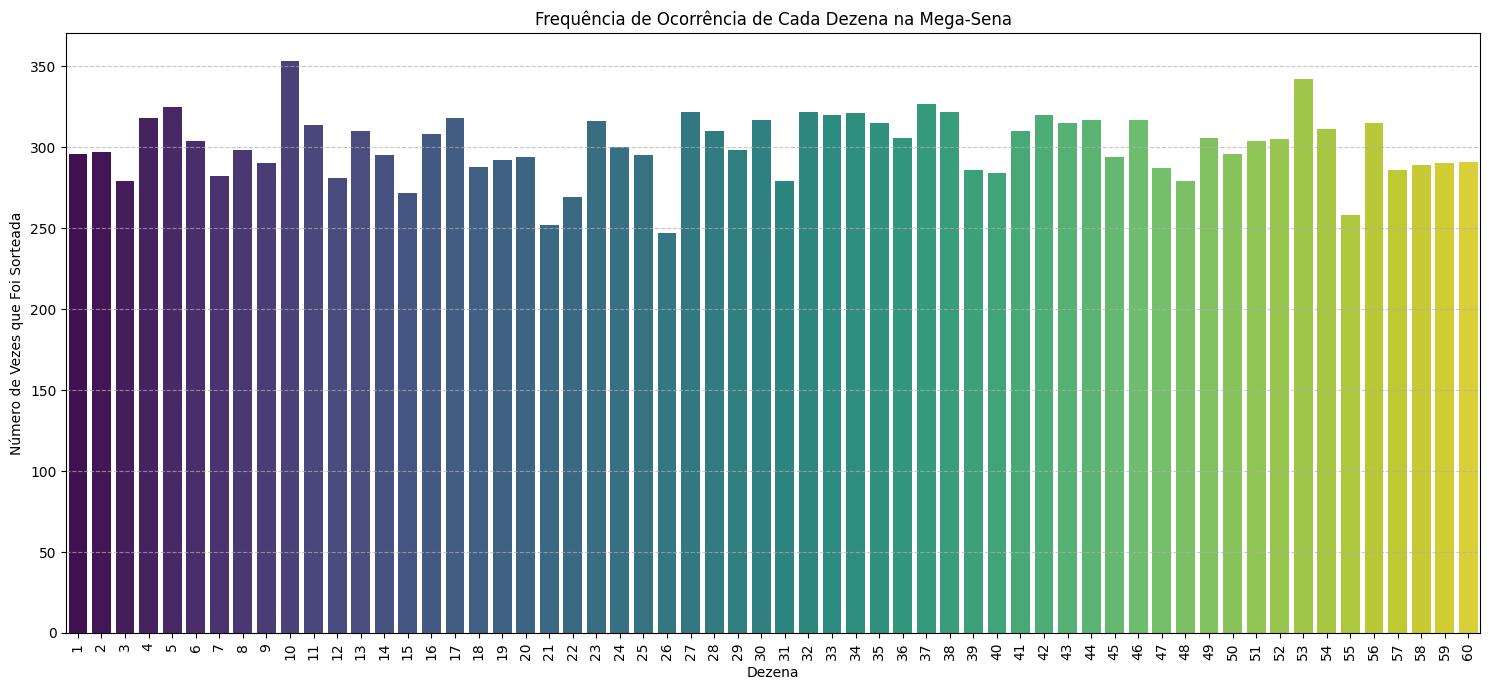

In [66]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Lista para armazenar todas as dezenas sorteadas
todas_dezenas = []

# Iterar sobre cada linha do DataFrame e coletar as dezenas
for index, row in df_mega_sena.iterrows():
    for col in colunas_bolas: # 'colunas_bolas' foi definida anteriormente e contém ['Bola1', ..., 'Bola6']
        todas_dezenas.append(row[col])

# Contar a frequência de cada dezena
frequencia_dezenas = Counter(todas_dezenas)

# Converter para um DataFrame para facilitar a visualização e ordenação
df_frequencia = pd.DataFrame(frequencia_dezenas.items(), columns=['Dezena', 'Frequencia'])

# Ordenar por dezena para uma visualização clara ou por frequência
df_frequencia = df_frequencia.sort_values(by='Dezena').reset_index(drop=True)

print("Frequência de cada dezena:")
display(df_frequencia.head(10))

# Plotar a frequência das dezenas
plt.figure(figsize=(15, 7))
sns.barplot(x='Dezena', y='Frequencia', data=df_frequencia, palette='viridis')
plt.title('Frequência de Ocorrência de Cada Dezena na Mega-Sena')
plt.xlabel('Dezena')
plt.ylabel('Número de Vezes que Foi Sorteada')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Cálculo do Desvio da Frequência das Dezenas

Agora vamos calcular o desvio da frequência de cada dezena em relação a uma 'média esperada', que é o número total de sorteios dividido por 10, conforme sua regra.

Total de sorteios analisados: 3009
Média esperada de ocorrências por dezena (total_sorteios / 10): 300.90

Frequência, Média Esperada e Desvio por Dezena:


,Dezena,Frequencia,Media_Esperada,Desvio
0,1,296,300.9,-4.9
1,2,297,300.9,-3.9
2,3,279,300.9,-21.9
3,4,318,300.9,17.1
4,5,325,300.9,24.1
5,6,304,300.9,3.1
6,7,282,300.9,-18.9
7,8,298,300.9,-2.9
8,9,290,300.9,-10.9
9,10,353,300.9,52.1


/tmp/ipykernel_3018/2858926245.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dezena', y='Desvio', data=df_frequencia, palette='coolwarm')


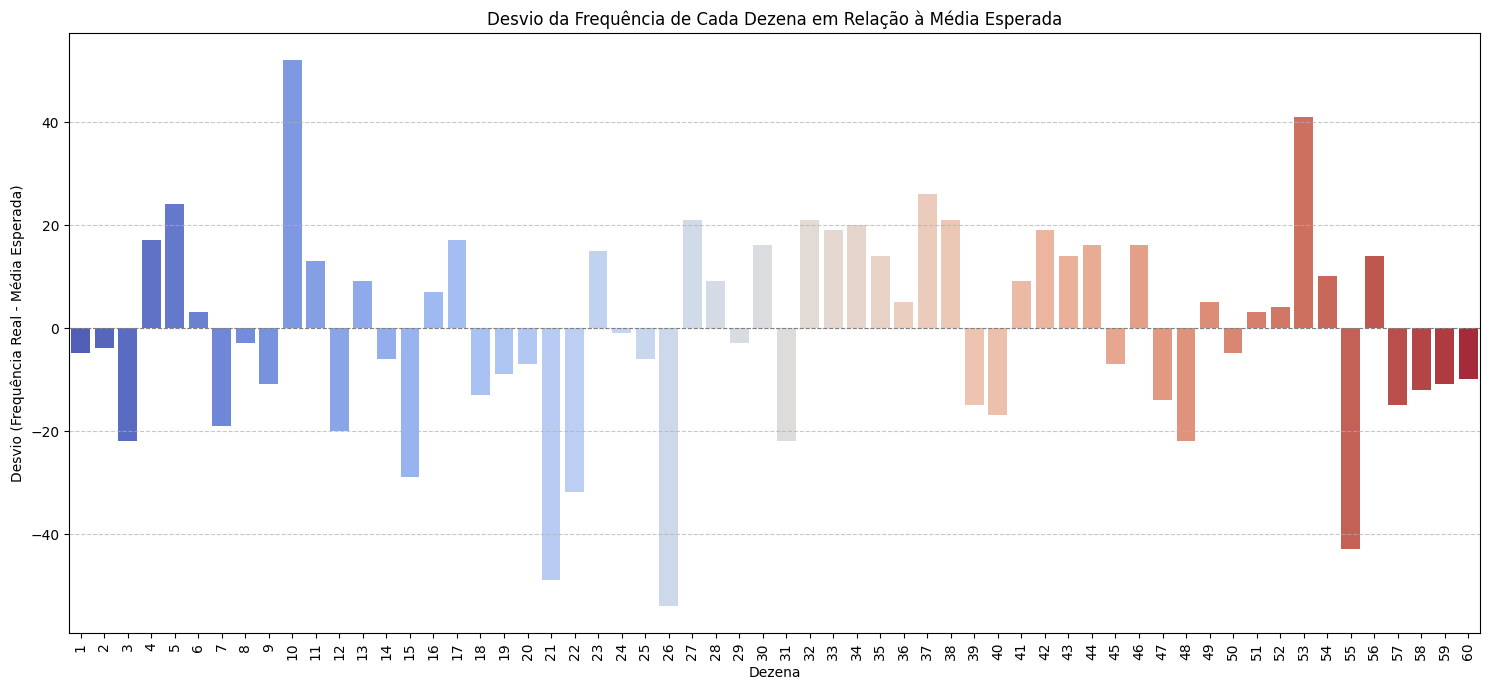

In [67]:
# Obter o número total de sorteios do DataFrame principal
total_sorteios = len(df_mega_sena)

# Calcular a média esperada de vezes que cada dezena deveria ter saído
media_esperada = total_sorteios / 10

print(f"Total de sorteios analisados: {total_sorteios}")
print(f"Média esperada de ocorrências por dezena (total_sorteios / 10): {media_esperada:.2f}")

# Adicionar a média esperada ao DataFrame de frequência (para referência)
df_frequencia['Media_Esperada'] = media_esperada

# Calcular o desvio: Frequencia Real - Média Esperada
df_frequencia['Desvio'] = df_frequencia['Frequencia'] - df_frequencia['Media_Esperada']

print("\nFrequência, Média Esperada e Desvio por Dezena:")
display(df_frequencia.head(10))

# Plotar o desvio das dezenas
plt.figure(figsize=(15, 7))
sns.barplot(x='Dezena', y='Desvio', data=df_frequencia, palette='coolwarm')
plt.title('Desvio da Frequência de Cada Dezena em Relação à Média Esperada')
plt.xlabel('Dezena')
plt.ylabel('Desvio (Frequência Real - Média Esperada)')
plt.xticks(rotation=90)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8) # Linha de referência no zero
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Dezenas com Maiores Desvios

Vamos ordenar o DataFrame `df_frequencia` pelo desvio para ver as dezenas que mais se afastaram da média esperada.

In [68]:
# Ordenar o DataFrame pelo 'Desvio' em ordem decrescente (maiores desvios primeiro)
df_frequencia_ordenada = df_frequencia.sort_values(by='Desvio', ascending=False).reset_index(drop=True)

print("As 10 dezenas com as maiores variações (maior desvio positivo ou menor desvio negativo):")
display(df_frequencia_ordenada.head(60))

print("\nAs 10 dezenas com as menores variações (maior desvio negativo ou menor desvio positivo):")
display(df_frequencia_ordenada.tail(60))

As 10 dezenas com as maiores variações (maior desvio positivo ou menor desvio negativo):


,Dezena,Frequencia,Media_Esperada,Desvio
0,10,353,300.9,52.1
1,53,342,300.9,41.1
2,37,327,300.9,26.1
3,5,325,300.9,24.1
4,32,322,300.9,21.1
5,38,322,300.9,21.1
6,27,322,300.9,21.1
7,34,321,300.9,20.1
8,33,320,300.9,19.1
9,42,320,300.9,19.1



As 10 dezenas com as menores variações (maior desvio negativo ou menor desvio positivo):


,Dezena,Frequencia,Media_Esperada,Desvio
0,10,353,300.9,52.1
1,53,342,300.9,41.1
2,37,327,300.9,26.1
3,5,325,300.9,24.1
4,32,322,300.9,21.1
5,38,322,300.9,21.1
6,27,322,300.9,21.1
7,34,321,300.9,20.1
8,33,320,300.9,19.1
9,42,320,300.9,19.1


### Análise de Sequências Consecutivas de Dezenas

Vamos agora analisar quantas vezes cada dezena saiu em concursos consecutivos. Esta análise mostrará qual é o maior número de vezes que uma dezena se manteve presente em sorteios seguidos.

Analisando sequências consecutivas de dezenas... Isso pode levar um momento.

Dezenas com as maiores sequências consecutivas (todos os resultados):


,Dezena,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1)
0,6,4,266,33
1,18,4,259,25
2,17,4,281,31
3,16,4,277,28
4,51,4,269,31
5,49,4,273,27
6,41,4,269,34
7,31,4,250,23
8,4,3,280,36
9,5,3,291,30


/tmp/ipykernel_3018/2450665235.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dezena', y='Máximo Consecutivo', data=df_max_consecutivo.sort_values(by='Dezena'), palette='plasma')


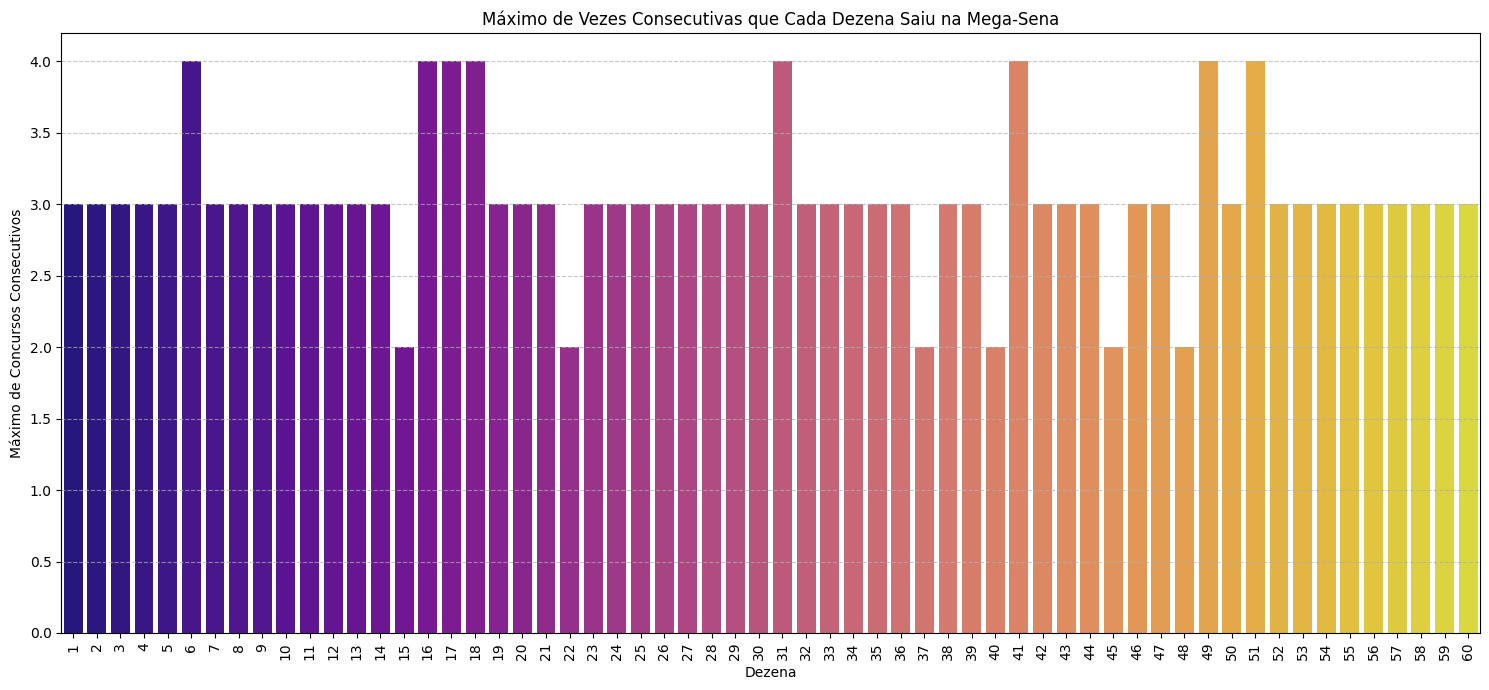

In [69]:
import pandas as pd

# Já temos 'df_mega_sena' e 'colunas_bolas' definidos nos passos anteriores.

# Dicionário para armazenar as sequências consecutivas para cada dezena
# Chave: dezena (1 a 60)
# Valor: lista de inteiros, onde cada inteiro representa o tamanho de uma sequência
sequencias_consecutivas = {dezena: [] for dezena in range(1, 61)}

# Dicionário temporário para acompanhar a contagem atual de cada dezena
contagem_atual_dezena = {dezena: 0 for dezena in range(1, 61)}

print("Analisando sequências consecutivas de dezenas... Isso pode levar um momento.")

# Iterar sobre cada sorteio (linha do DataFrame)
for index, row in df_mega_sena.iterrows():
    # Conjunto de dezenas presentes no sorteio atual
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])

    # Atualizar as contagens para cada dezena de 1 a 60
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            # Se a dezena está presente, incrementa a contagem atual
            contagem_atual_dezena[dezena] += 1
        else:
            # Se a dezena NÃO está presente, a sequência é quebrada
            # Se a contagem atual for maior que zero, significa que havia uma sequência ativa
            if contagem_atual_dezena[dezena] > 0:
                sequencias_consecutivas[dezena].append(contagem_atual_dezena[dezena])
            # Reseta a contagem para esta dezena
            contagem_atual_dezena[dezena] = 0

# Após o loop, é preciso verificar se há sequências pendentes (que terminaram no último sorteio)
for dezena in range(1, 61):
    if contagem_atual_dezena[dezena] > 0:
        sequencias_consecutivas[dezena].append(contagem_atual_dezena[dezena])

# Preparar os resultados para exibição em um DataFrame
dados_max_consecutivo = []
for dezena, sequencias in sequencias_consecutivas.items():
    max_consecutivo = max(sequencias) if sequencias else 0
    total_sequencias_registradas = len(sequencias)
    # Considerar apenas sequências de 2 ou mais para "maior que 1" como o usuário pediu
    total_sequencias_maior_que_1 = sum(1 for s in sequencias if s > 1)

    dados_max_consecutivo.append({
        'Dezena': dezena,
        'Máximo Consecutivo': max_consecutivo,
        'Total de Sequências (qualquer tamanho)': total_sequencias_registradas,
        'Total de Sequências (> 1)': total_sequencias_maior_que_1
    })

df_max_consecutivo = pd.DataFrame(dados_max_consecutivo)

# Ordenar para melhor visualização, por exemplo, pelas dezenas com maior número consecutivo
df_max_consecutivo = df_max_consecutivo.sort_values(by='Máximo Consecutivo', ascending=False).reset_index(drop=True)

print("\nDezenas com as maiores sequências consecutivas (todos os resultados):")
display(df_max_consecutivo) # Modificado para exibir todo o DataFrame

# Opcional: Visualização gráfica
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))
sns.barplot(x='Dezena', y='Máximo Consecutivo', data=df_max_consecutivo.sort_values(by='Dezena'), palette='plasma')
plt.title('Máximo de Vezes Consecutivas que Cada Dezena Saiu na Mega-Sena')
plt.xlabel('Dezena')
plt.ylabel('Máximo de Concursos Consecutivos')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Análise de Ausência Consecutiva de Dezenas

Vamos calcular o número máximo de sorteios que cada dezena ficou sem ser sorteada consecutivamente.

Analisando ausências consecutivas de dezenas... Isso pode levar um momento.

Dezenas com as maiores sequências de ausência consecutiva:


,Dezena,Máximo de Sorteios Sem Sair
0,42,108
1,26,88
2,19,82
3,25,80
4,40,78
5,49,78
6,38,77
7,50,75
8,51,75
9,32,73


/tmp/ipykernel_3018/3036512349.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dezena', y='Máximo de Sorteios Sem Sair', data=df_max_ausencia.sort_values(by='Dezena'), palette='coolwarm')


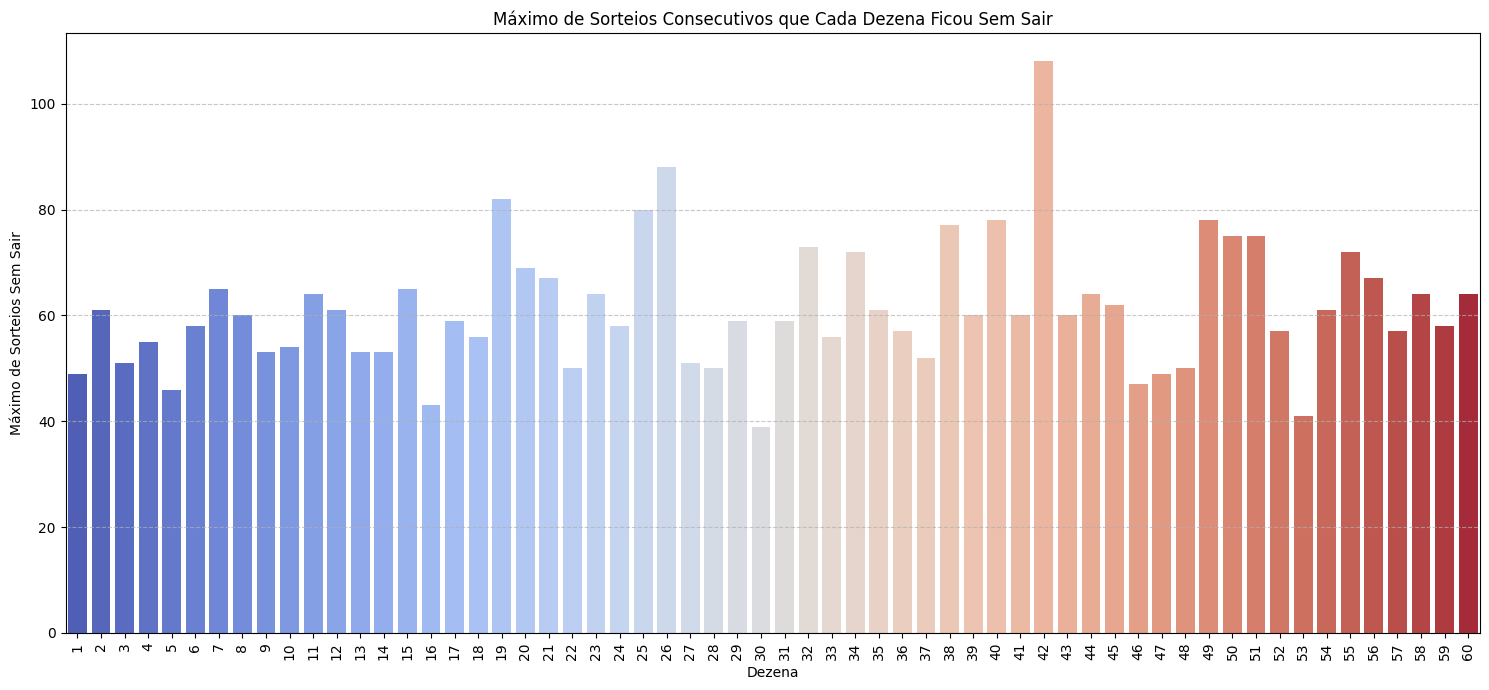

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Já temos 'df_mega_sena' e 'colunas_bolas' definidos anteriormente.

# Dicionário para armazenar o máximo de vezes consecutivas que uma dezena não saiu
max_ausencia_consecutiva = {dezena: 0 for dezena in range(1, 61)}
# Dicionário temporário para acompanhar a contagem atual de ausência para cada dezena
current_ausencia_consecutiva = {dezena: 0 for dezena in range(1, 61)}

print("Analisando ausências consecutivas de dezenas... Isso pode levar um momento.")

# Iterar sobre cada sorteio (linha do DataFrame)
for index, row in df_mega_sena.iterrows():
    # Conjunto de dezenas presentes no sorteio atual
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])

    # Atualizar as contagens para cada dezena de 1 a 60
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            # Se a dezena está presente, a sequência de ausência é quebrada
            current_ausencia_consecutiva[dezena] = 0
        else:
            # Se a dezena NÃO está presente, incrementa a contagem de ausência
            current_ausencia_consecutiva[dezena] += 1
            # Atualiza o máximo de ausência consecutiva se a contagem atual for maior
            max_ausencia_consecutiva[dezena] = max(
                max_ausencia_consecutiva[dezena],
                current_ausencia_consecutiva[dezena]
            )

# Preparar os resultados para exibição em um DataFrame
dados_max_ausencia = []
for dezena, max_ausencia in max_ausencia_consecutiva.items():
    dados_max_ausencia.append({
        'Dezena': dezena,
        'Máximo de Sorteios Sem Sair': max_ausencia
    })

df_max_ausencia = pd.DataFrame(dados_max_ausencia)

# Ordenar para melhor visualização, por exemplo, pelas dezenas com maior número consecutivo de ausência
df_max_ausencia = df_max_ausencia.sort_values(by='Máximo de Sorteios Sem Sair', ascending=False).reset_index(drop=True)

print("\nDezenas com as maiores sequências de ausência consecutiva:")
display(df_max_ausencia)

# Plotar o máximo de ausência consecutiva das dezenas
plt.figure(figsize=(15, 7))
sns.barplot(x='Dezena', y='Máximo de Sorteios Sem Sair', data=df_max_ausencia.sort_values(by='Dezena'), palette='coolwarm')
plt.title('Máximo de Sorteios Consecutivos que Cada Dezena Ficou Sem Sair')
plt.xlabel('Dezena')
plt.ylabel('Máximo de Sorteios Sem Sair')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Detalhes da Maior Ausência Consecutiva para a Dezena 42

Conforme identificado, a dezena 42 teve uma ausência recorde de 108 sorteios consecutivos. Vamos verificar e exibir esses sorteios.

In [71]:
dezena_alvo = 42
max_ausencia_esperada = 108 # Confirmado a partir de df_max_ausencia

current_ausencia_count = 0
start_concurso_ausencia = None
end_concurso_ausencia = None

lista_concursos_ausentes = []

print(f"Buscando a sequência de {max_ausencia_esperada} sorteios consecutivos sem a dezena {dezena_alvo}...")

# Certifique-se de que df_mega_sena está ordenado por 'Concurso'
df_mega_sena_sorted = df_mega_sena.sort_values(by='Concurso').reset_index(drop=True)

for index, row in df_mega_sena_sorted.iterrows():
    concurso_atual = row['Concurso']
    dezenas_no_sorteio = [row[col] for col in colunas_bolas]

    if dezena_alvo not in dezenas_no_sorteio:
        # Dezena 42 não está no sorteio atual
        if current_ausencia_count == 0:
            start_concurso_ausencia = concurso_atual
        current_ausencia_count += 1
        lista_concursos_ausentes.append(concurso_atual)

    else:
        # Dezena 42 está presente, a sequência de ausência foi quebrada
        if current_ausencia_count == max_ausencia_esperada:
            end_concurso_ausencia = concurso_atual - 1 # O sorteio anterior foi o último da sequência
            print(f"Sequência encontrada: {max_ausencia_esperada} sorteios sem a dezena {dezena_alvo}.")
            print(f"Início: Concurso {start_concurso_ausencia}, Fim: Concurso {end_concurso_ausencia}")
            break # Encontramos a sequência, podemos parar

        # Resetar para a próxima sequência
        current_ausencia_count = 0
        lista_concursos_ausentes = []

# Se a sequência de 108 sorteios foi encontrada e processada, podemos exibir os dados
if start_concurso_ausencia is not None and end_concurso_ausencia is not None:
    print(f"\nExibindo detalhes dos sorteios de {start_concurso_ausencia} a {end_concurso_ausencia} onde a dezena {dezena_alvo} esteve ausente:")
    # Filtrar o DataFrame original para esses concursos
    df_ausencia_42 = df_mega_sena_sorted[(df_mega_sena_sorted['Concurso'] >= start_concurso_ausencia) &
                                        (df_mega_sena_sorted['Concurso'] <= end_concurso_ausencia)]
    display(df_ausencia_42[['Concurso', 'Data do Sorteio'] + colunas_bolas])
else:
    print("Não foi possível encontrar a sequência exata de 108 sorteios para a dezena 42 com este método de busca.")
    print("Isso pode ocorrer se a sequência terminar no último sorteio do dataset ou se houver alguma inconsistência.")

Buscando a sequência de 108 sorteios consecutivos sem a dezena 42...
Sequência encontrada: 108 sorteios sem a dezena 42.
Início: Concurso 2505, Fim: Concurso 2612

Exibindo detalhes dos sorteios de 2505 a 2612 onde a dezena 42 esteve ausente:


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6
2504,2505,30/07/2022,3,5,19,26,43,51
2505,2506,02/08/2022,21,22,29,34,40,44
2506,2507,04/08/2022,4,6,12,34,35,53
2507,2508,06/08/2022,41,45,48,51,53,58
2508,2509,10/08/2022,8,37,39,50,59,60
...,...,...,...,...,...,...,...,...
2607,2608,05/07/2023,7,13,17,24,29,52
2608,2609,08/07/2023,3,21,27,32,35,60
2609,2610,12/07/2023,10,23,34,53,55,57
2610,2611,15/07/2023,4,12,18,21,25,49


In [72]:
pd.set_option('display.max_rows', None)
display(df_ausencia_42[['Concurso', 'Data do Sorteio'] + colunas_bolas])
pd.reset_option('display.max_rows')

,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6
2504,2505,30/07/2022,3,5,19,26,43,51
2505,2506,02/08/2022,21,22,29,34,40,44
2506,2507,04/08/2022,4,6,12,34,35,53
2507,2508,06/08/2022,41,45,48,51,53,58
2508,2509,10/08/2022,8,37,39,50,59,60
2509,2510,13/08/2022,8,13,25,32,44,57
2510,2511,17/08/2022,4,10,15,39,41,49
2511,2512,20/08/2022,7,10,34,47,49,52
2512,2513,24/08/2022,13,19,21,35,46,50
2513,2514,27/08/2022,5,15,24,34,45,52


### Probabilidade de Ausência de uma Dezena

Vamos calcular a probabilidade de uma dezena específica não ser sorteada em um determinado número de concursos. Usaremos tanto a probabilidade teórica quanto a empírica (baseada na frequência histórica).

In [73]:
from math import comb

# --- 1. Probabilidade Teórica (Ideal) ---

# Número total de dezenas = 60
# Número de dezenas sorteadas por concurso = 6

# Probabilidade de uma dezena ESPECÍFICA ser sorteada em um concurso:
# Combinações onde a dezena X está presente: Escolhemos 5 números das 59 restantes.
# Combinações totais:
prob_dezena_sorteada_teorica = (comb(59, 5)) / comb(60, 6)
# Simplificando, é 6/60 = 1/10

print(f"Probabilidade TEÓRICA de uma dezena específica ser sorteada em um concurso: {prob_dezena_sorteada_teorica:.4f}")

# Probabilidade TEÓRICA de uma dezena específica NÃO ser sorteada em um concurso:
prob_dezena_nao_sorteada_teorica = 1 - prob_dezena_sorteada_teorica
print(f"Probabilidade TEÓRICA de uma dezena específica NÃO ser sorteada em um concurso: {prob_dezena_nao_sorteada_teorica:.4f}")

# Probabilidade TEÓRICA de uma dezena específica NÃO ser sorteada em 1108 concursos consecutivos:
prob_nao_sorteada_1108_teorica = prob_dezena_nao_sorteada_teorica ** 1108
print(f"Probabilidade TEÓRICA de uma dezena NÃO ser sorteada em 1108 concursos: {prob_nao_sorteada_1108_teorica:.10e}")

# --- 2. Probabilidade Empírica (Baseada nos Dados Históricos) ---

# 'df_frequencia' e 'total_sorteios' já foram definidos anteriormente.

# Calcular a probabilidade empírica de CADA dezena NÃO ser sorteada em um único concurso
df_frequencia['Prob_Nao_Sair_Empirica_1_Concurso'] = 1 - (df_frequencia['Frequencia'] / total_sorteios)

# Calcular a probabilidade empírica de CADA dezena NÃO ser sorteada em 1108 concursos consecutivos
df_frequencia['Prob_Nao_Sair_Empirica_1108_Concursos'] = df_frequencia['Prob_Nao_Sair_Empirica_1_Concurso'] ** 1108

# Encontrar as probabilidades máxima e mínima empíricas para 1108 concursos
max_prob_empirica_1108 = df_frequencia['Prob_Nao_Sair_Empirica_1108_Concursos'].max()
min_prob_empirica_1108 = df_frequencia['Prob_Nao_Sair_Empirica_1108_Concursos'].min()

dezena_max_prob = df_frequencia.loc[df_frequencia['Prob_Nao_Sair_Empirica_1108_Concursos'].idxmax()]
dezena_min_prob = df_frequencia.loc[df_frequencia['Prob_Nao_Sair_Empirica_1108_Concursos'].idxmin()]


print("\n--- Análise Empírica ---")
print(f"Maior probabilidade EMPÍRICA de ausência por 1108 concursos: {max_prob_empirica_1108:.10e} (Dezena {int(dezena_max_prob['Dezena'])} com frequência {int(dezena_max_prob['Frequencia'])}/3007)")
print(f"Menor probabilidade EMPÍRICA de ausência por 1108 concursos: {min_prob_empirica_1108:.10e} (Dezena {int(dezena_min_prob['Dezena'])} com frequência {int(dezena_min_prob['Frequencia'])}/3007)")

print("\nObservação: A probabilidade teórica assume que cada sorteio é independente e todas as dezenas têm a mesma chance de serem sorteadas. A probabilidade empírica reflete o comportamento observado nos dados históricos.")

Probabilidade TEÓRICA de uma dezena específica ser sorteada em um concurso: 0.1000
Probabilidade TEÓRICA de uma dezena específica NÃO ser sorteada em um concurso: 0.9000
Probabilidade TEÓRICA de uma dezena NÃO ser sorteada em 1108 concursos: 1.9984830021e-51

--- Análise Empírica ---
Maior probabilidade EMPÍRICA de ausência por 1108 concursos: 6.0820088087e-42 (Dezena 26 com frequência 247/3007)
Menor probabilidade EMPÍRICA de ausência por 1108 concursos: 8.9726001627e-61 (Dezena 10 com frequência 353/3007)

Observação: A probabilidade teórica assume que cada sorteio é independente e todas as dezenas têm a mesma chance de serem sorteadas. A probabilidade empírica reflete o comportamento observado nos dados históricos.


### Análise de Dezenas em Sorteios Recentes (4 Vezes Consecutivas)

Vamos agora verificar se alguma dezena apareceu nos últimos 4 concursos consecutivos, ou seja, no sorteio `N`, `N-1`, `N-2` e `N-3`.

In [74]:
import pandas as pd

# Certificar que o DataFrame está ordenado por Concurso
df_sorted_concurso = df_mega_sena.sort_values(by='Concurso', ascending=False)

# Pegar os últimos 4 concursos
ultimos_4_concursos = df_sorted_concurso.head(4)

# Lista para armazenar os conjuntos de dezenas de cada concurso
listas_dezenas_ultimos_4 = []

# Extrair as dezenas de cada um dos 4 concursos e converter para conjuntos
for index, row in ultimos_4_concursos.iterrows():
    dezenas = {row[col] for col in colunas_bolas} # 'colunas_bolas' já está definida
    listas_dezenas_ultimos_4.append(dezenas)

# Encontrar a interseção (números comuns) entre todos esses conjuntos
if listas_dezenas_ultimos_4:
    dezenas_em_comum = set.intersection(*listas_dezenas_ultimos_4)
else:
    dezenas_em_comum = set()

print(f"Analisando os concursos: {ultimos_4_concursos['Concurso'].tolist()}")

if dezenas_em_comum:
    print(f"\nAs seguintes dezenas apareceram em 4 concursos consecutivos: {sorted(list(dezenas_em_comum))}")
else:
    print("\nNenhuma dezena apareceu em 4 concursos consecutivos (N, N-1, N-2, N-3).")


Analisando os concursos: [3009, 3008, 3007, 3006]

Nenhuma dezena apareceu em 4 concursos consecutivos (N, N-1, N-2, N-3).


### Análise de Ausências Extremas em Concursos Recentes

Com base na análise anterior de 'Máximo de Sorteios Sem Sair', vamos verificar especificamente as dezenas que superaram 108 ou 39 ausências consecutivas.

In [75]:
# Filtrar dezenas com ausência consecutiva maior que 108
dezenas_mais_de_108_ausencias = df_max_ausencia[df_max_ausencia['Máximo de Sorteios Sem Sair'] > 108]

# Filtrar dezenas com ausência consecutiva maior que 39
dezenas_mais_de_39_ausencias = df_max_ausencia[df_max_ausencia['Máximo de Sorteios Sem Sair'] > 39]

print("Dezenas com mais de 108 sorteios consecutivos sem sair:")
if not dezenas_mais_de_108_ausencias.empty:
    display(dezenas_mais_de_108_ausencias)
else:
    print("Nenhuma dezena ficou mais de 108 sorteios consecutivos sem sair.")

print("\nDezenas com mais de 39 sorteios consecutivos sem sair (incluindo as de >108 se houver):")
if not dezenas_mais_de_39_ausencias.empty:
    display(dezenas_mais_de_39_ausencias)
else:
    print("Nenhuma dezena ficou mais de 39 sorteios consecutivos sem sair.")

Dezenas com mais de 108 sorteios consecutivos sem sair:
Nenhuma dezena ficou mais de 108 sorteios consecutivos sem sair.

Dezenas com mais de 39 sorteios consecutivos sem sair (incluindo as de >108 se houver):


,Dezena,Máximo de Sorteios Sem Sair
0,42,108
1,26,88
2,19,82
3,25,80
4,40,78
5,49,78
6,38,77
7,50,75
8,51,75
9,32,73


### Análise da Ausência Atual de Dezenas (Considerando o Último Sorteio)

Vamos recalcular a ausência consecutiva de cada dezena, focando na sua situação atual (a partir do último concurso registrado).

In [76]:
import pandas as pd

# Certificar que o DataFrame está ordenado por Concurso
df_mega_sena_sorted = df_mega_sena.sort_values(by='Concurso').reset_index(drop=True)

# Dicionário para armazenar a contagem atual de ausência para cada dezena
current_ausencia_count_final = {dezena: 0 for dezena in range(1, 61)}

print("Calculando a ausência consecutiva atual de cada dezena...")

# Iterar sobre cada sorteio (linha do DataFrame)
for index, row in df_mega_sena_sorted.iterrows():
    # Conjunto de dezenas presentes no sorteio atual
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])

    # Atualizar as contagens para cada dezena de 1 a 60
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            # Se a dezena está presente, a sequência de ausência é quebrada
            current_ausencia_count_final[dezena] = 0
        else:
            # Se a dezena NÃO está presente, incrementa a contagem de ausência
            current_ausencia_count_final[dezena] += 1

# Preparar os resultados para exibição em um DataFrame
df_current_ausencia = pd.DataFrame(current_ausencia_count_final.items(),
                                     columns=['Dezena', 'Ausencia_Atual_Concursos'])

# Ordenar para melhor visualização
df_current_ausencia = df_current_ausencia.sort_values(by='Ausencia_Atual_Concursos', ascending=False).reset_index(drop=True)

print("\nAusência consecutiva atual de cada dezena (terminando no último concurso):")
display(df_current_ausencia.head(10))

# --- Filtrar as dezenas com ausência atual maior que 108 ou 39 ---

# Dezenas com ausência atual maior que 108
dezenas_ausencia_atual_maior_108 = df_current_ausencia[df_current_ausencia['Ausencia_Atual_Concursos'] > 108]

# Dezenas com ausência atual maior que 39
dezenas_ausencia_atual_maior_39 = df_current_ausencia[df_current_ausencia['Ausencia_Atual_Concursos'] > 39]

print("\nDezenas com ausência ATUAL consecutiva maior que 108 sorteios:")
if not dezenas_ausencia_atual_maior_108.empty:
    display(dezenas_ausencia_atual_maior_108)
else:
    print("Nenhuma dezena está atualmente ausente por mais de 108 sorteios.")

print("\nDezenas com ausência ATUAL consecutiva maior que 39 sorteios:")
if not dezenas_ausencia_atual_maior_39.empty:
    display(dezenas_ausencia_atual_maior_39)
else:
    print("Nenhuma dezena está atualmente ausente por mais de 39 sorteios.")

Calculando a ausência consecutiva atual de cada dezena...

Ausência consecutiva atual de cada dezena (terminando no último concurso):


,Dezena,Ausencia_Atual_Concursos
0,34,46
1,2,27
2,35,27
3,41,23
4,46,22
5,16,22
6,57,21
7,56,20
8,53,18
9,33,17



Dezenas com ausência ATUAL consecutiva maior que 108 sorteios:
Nenhuma dezena está atualmente ausente por mais de 108 sorteios.

Dezenas com ausência ATUAL consecutiva maior que 39 sorteios:


,Dezena,Ausencia_Atual_Concursos
0,34,46


### Análise de Frequência de Sequências de Ausência para Cada Dezena

Conforme solicitado, vamos criar uma 'matriz de probabilidade' que, na verdade, será uma **matriz de frequência das durações das sequências de ausência** para cada dezena. Isso nos permitirá ver quantas vezes cada dezena ficou 1, 2, 3... N sorteios sem aparecer, registrando cada ocorrência de uma sequência de ausência de um determinado comprimento.

Esta análise detalhada responde à sua pergunta sobre como registrar e somar cada ocorrência de ausência de um determinado número de vezes, sem que a contagem de 'quantas vezes ficou X sorteios sem sair' seja repetida, mas sim somando as *ocorrências* de cada comprimento de sequência.

In [77]:
# Certificar que o DataFrame está ordenado por Concurso
df_mega_sena_sorted = df_mega_sena.sort_values(by='Concurso').reset_index(drop=True)

# Dicionário para armazenar TODAS as sequências de ausência para cada dezena
# Ex: {1: [10, 30, 40, 30], 2: [5, 12, 8], ...}
all_absence_streaks_per_dezena = {dezena: [] for dezena in range(1, 61)}

# Dicionário temporário para acompanhar a contagem atual de ausência para cada dezena
current_absence_count_tracker = {dezena: 0 for dezena in range(1, 61)}

print("Coletando todas as sequências de ausência para cada dezena... Isso pode levar alguns segundos.")

# Iterar sobre cada sorteio (linha do DataFrame)
for index, row in df_mega_sena_sorted.iterrows():
    dezenas_present_in_draw = set(row[col] for col in colunas_bolas)

    for dezena in range(1, 61):
        if dezena in dezenas_present_in_draw:
            # Se a dezena está presente, a sequência de ausência é quebrada
            # Se a contagem atual for maior que zero, significa que havia uma sequência ativa
            if current_absence_count_tracker[dezena] > 0:
                all_absence_streaks_per_dezena[dezena].append(current_absence_count_tracker[dezena])
            current_absence_count_tracker[dezena] = 0
        else:
            # Se a dezena NÃO está presente, incrementa a contagem de ausência
            current_absence_count_tracker[dezena] += 1

# Após o loop, é preciso verificar se há sequências pendentes (que terminaram no último sorteio)
# ou se a dezena está atualmente em uma sequência de ausência
for dezena in range(1, 61):
    if current_absence_count_tracker[dezena] > 0:
        all_absence_streaks_per_dezena[dezena].append(current_absence_count_tracker[dezena])

print("Coleta de sequências de ausência concluída.")


Coletando todas as sequências de ausência para cada dezena... Isso pode levar alguns segundos.
Coleta de sequências de ausência concluída.


In [78]:
from collections import Counter

# Determinar o comprimento máximo de uma sequência de ausência observada
max_observed_streak_length = 0
for dezena, streaks in all_absence_streaks_per_dezena.items():
    if streaks:
        max_observed_streak_length = max(max_observed_streak_length, max(streaks))

# Preparar as colunas para o DataFrame de frequência
# 'Dezena' + comprimentos de sequência de 1 até o máximo observado
columns_for_df = ['Dezena'] + list(range(1, max_observed_streak_length + 1))

# Criar o DataFrame de frequência
df_absence_streaks_frequency = pd.DataFrame(columns=columns_for_df)

# Preencher o DataFrame
rows_data = []
for dezena in range(1, 61):
    streak_counts = Counter(all_absence_streaks_per_dezena[dezena])

    row_entry = {'Dezena': dezena}
    for streak_len in range(1, max_observed_streak_length + 1):
        row_entry[streak_len] = streak_counts.get(streak_len, 0) # 0 se não houver ocorrência

    # Adicionar estatísticas de resumo
    total_streaks = sum(streak_counts.values())
    total_absence_draws = sum(s * c for s, c in streak_counts.items())
    average_streak_length = total_absence_draws / total_streaks if total_streaks > 0 else 0

    row_entry['Total_Streaks_Observed'] = total_streaks
    row_entry['Total_Absence_Draws'] = total_absence_draws
    row_entry['Average_Streak_Length'] = average_streak_length

    rows_data.append(row_entry)

df_absence_streaks_frequency = pd.DataFrame(rows_data)

print(f"Matriz de Frequência de Sequências de Ausência (60 dezenas x {max_observed_streak_length} comprimentos de sequência + 3 colunas de resumo):")
display(df_absence_streaks_frequency.head())

print("\nDezena com a maior quantidade total de sorteios em ausência:")
display(df_absence_streaks_frequency.sort_values(by='Total_Absence_Draws', ascending=False).head(5))

print("\nDezena com o maior comprimento médio de sequência de ausência:")
display(df_absence_streaks_frequency.sort_values(by='Average_Streak_Length', ascending=False).head(5))

Matriz de Frequência de Sequências de Ausência (60 dezenas x 108 comprimentos de sequência + 3 colunas de resumo):


,Dezena,1,2,3,4,5,6,7,8,9,...,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
0,1,25,32,20,19,18,15,12,11,17,...,0,0,0,0,0,0,0,273,2713,9.937729
1,2,26,28,18,20,17,13,14,12,12,...,0,0,0,0,0,0,0,267,2712,10.157303
2,3,20,28,26,16,11,10,10,14,13,...,0,0,0,0,0,0,0,254,2730,10.748031
3,4,33,31,28,23,15,17,10,10,6,...,0,0,0,0,0,0,0,279,2691,9.645161
4,5,20,33,24,25,21,24,15,17,14,...,0,0,0,0,0,0,0,291,2684,9.223368



Dezena com a maior quantidade total de sorteios em ausência:


,Dezena,1,2,3,4,5,6,7,8,9,...,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
25,26,17,26,11,12,14,13,12,11,13,...,0,0,0,0,0,0,0,238,2762,11.605042
20,21,28,19,20,12,11,15,12,11,9,...,0,0,0,0,0,0,0,237,2757,11.632911
54,55,29,11,17,13,10,22,6,11,11,...,0,0,0,0,0,0,0,239,2751,11.510460
21,22,16,18,27,16,17,9,16,14,8,...,0,0,0,0,0,0,0,252,2740,10.873016
14,15,24,24,17,17,15,11,11,14,12,...,0,0,0,0,0,0,0,246,2737,11.126016



Dezena com o maior comprimento médio de sequência de ausência:


,Dezena,1,2,3,4,5,6,7,8,9,...,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
20,21,28,19,20,12,11,15,12,11,9,...,0,0,0,0,0,0,0,237,2757,11.632911
25,26,17,26,11,12,14,13,12,11,13,...,0,0,0,0,0,0,0,238,2762,11.605042
54,55,29,11,17,13,10,22,6,11,11,...,0,0,0,0,0,0,0,239,2751,11.510460
14,15,24,24,17,17,15,11,11,14,12,...,0,0,0,0,0,0,0,246,2737,11.126016
30,31,20,18,18,18,12,19,15,7,12,...,0,0,0,0,0,0,0,251,2730,10.876494


### Interpretação da Matriz de Frequência e Derivação de Probabilidades

Cada linha na tabela acima representa uma dezena. As colunas numeradas (ex: `1`, `2`, `3`... até `108`) indicam o **número de vezes que aquela dezena específica ficou ausente por X sorteios consecutivos**.

*   **Por exemplo:** Se para a `Dezena 1` a coluna `10` mostrar `3`, significa que a Dezena 1 ficou ausente por exatamente 10 sorteios consecutivos em 3 ocasiões distintas ao longo do histórico.

As colunas de resumo fornecem informações adicionais:
*   `Total_Streaks_Observed`: O número total de sequências de ausência (de qualquer comprimento) registradas para aquela dezena.
*   `Total_Absence_Draws`: A soma de todos os sorteios em que a dezena esteve ausente, considerando todas as suas sequências (ex: uma sequência de 10 + uma de 30 + uma de 40 + uma de 30 = 110 sorteios de ausência).
*   `Average_Streak_Length`: O comprimento médio das sequências de ausência para aquela dezena.

#### Como derivar 'probabilidades' desta matriz:

Para transformar estas frequências em probabilidades, você pode:

1.  **Probabilidade de uma dezena ter uma sequência de ausência de um certo comprimento *dado que ela teve uma sequência de ausência***: Divida o valor da célula (frequência de um comprimento de sequência X) pelo `Total_Streaks_Observed` para aquela dezena.
    *   `P(streak_len=X | dezena Y had a streak) = df_absence_streaks_frequency.loc[df_absence_streaks_frequency['Dezena'] == Y, X] / df_absence_streaks_frequency.loc[df_absence_streaks_frequency['Dezena'] == Y, 'Total_Streaks_Observed']`

2.  **Probabilidade de uma dezena ter uma sequência de ausência de um certo comprimento *em qualquer sorteio***: Divida o valor da célula (frequência de um comprimento de sequência X) pelo `total_sorteios` (o número total de sorteios no seu dataset).
    *   `P(streak_len=X for dezena Y) = df_absence_streaks_frequency.loc[df_absence_streaks_frequency['Dezena'] == Y, X] / total_sorteios`

Esta matriz oferece uma visão rica sobre o comportamento de ausência de cada dezena, permitindo identificar padrões e tendências.

Média do comprimento de sequência de ausência para cada dezena:


,Dezena,Average_Streak_Length
0,1,9.937729
1,2,10.157303
2,3,10.748031
3,4,9.645161
4,5,9.223368
5,6,10.169173
6,7,10.821429
7,8,10.153558
8,9,10.538760
9,10,8.326019


/tmp/ipykernel_3018/2733872584.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Dezena', y='Average_Streak_Length', data=average_streak_length_per_dezena, palette='viridis')


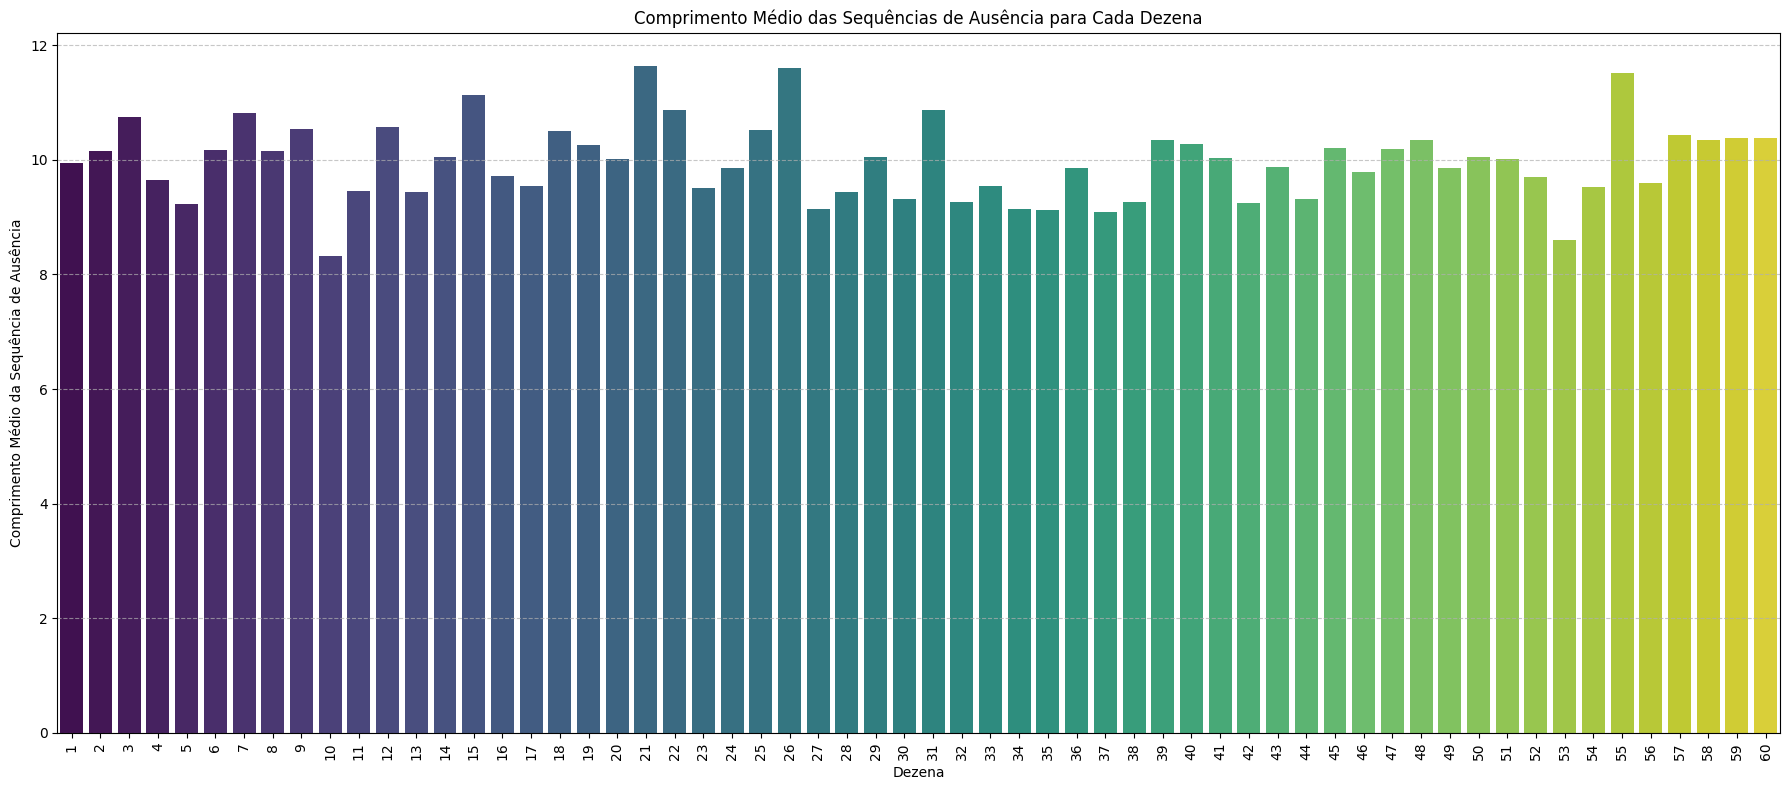

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean (average) length of absence streaks for each dezena
# This is already available in the 'Average_Streak_Length' column
average_streak_length_per_dezena = df_absence_streaks_frequency[['Dezena', 'Average_Streak_Length']]

print("Média do comprimento de sequência de ausência para cada dezena:")
display(average_streak_length_per_dezena.head(10))

# Visualize the average absence streak length for each dezena
plt.figure(figsize=(18, 8))
sns.barplot(x='Dezena', y='Average_Streak_Length', data=average_streak_length_per_dezena, palette='viridis')
plt.title('Comprimento Médio das Sequências de Ausência para Cada Dezena')
plt.xlabel('Dezena')
plt.ylabel('Comprimento Médio da Sequência de Ausência')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [80]:
import pandas as pd

# Começar com df_frequencia como base
df_consolidado = df_frequencia.copy()

# Merge com df_max_consecutivo
df_consolidado = pd.merge(df_consolidado,
                          df_max_consecutivo[['Dezena', 'Máximo Consecutivo', 'Total de Sequências (qualquer tamanho)', 'Total de Sequências (> 1)']],
                          on='Dezena', how='left')

# Merge com df_max_ausencia
df_consolidado = pd.merge(df_consolidado,
                          df_max_ausencia[['Dezena', 'Máximo de Sorteios Sem Sair']],
                          on='Dezena', how='left')

# Merge com df_current_ausencia
df_consolidado = pd.merge(df_consolidado,
                          df_current_ausencia[['Dezena', 'Ausencia_Atual_Concursos']],
                          on='Dezena', how='left')

# Merge com df_absence_streaks_frequency
df_consolidado = pd.merge(df_consolidado,
                          df_absence_streaks_frequency,
                          on='Dezena', how='left')

print("DataFrame Consolidado com todas as análises por Dezena:")
display(df_consolidado.head())

DataFrame Consolidado com todas as análises por Dezena:


,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,...,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
0,1,296,300.9,-4.9,0.901628,1.481111e-50,3,272,23,49,...,0,0,0,0,0,0,0,273,2713,9.937729
1,2,297,300.9,-3.9,0.901296,9.844353e-51,3,266,30,61,...,0,0,0,0,0,0,0,267,2712,10.157303
2,3,279,300.9,-21.9,0.907278,1.501167e-47,3,253,24,51,...,0,0,0,0,0,0,0,254,2730,10.748031
3,4,318,300.9,17.1,0.894317,1.788929e-54,3,280,36,55,...,0,0,0,0,0,0,0,279,2691,9.645161
4,5,325,300.9,24.1,0.891991,9.982486e-56,3,291,30,46,...,0,0,0,0,0,0,0,291,2684,9.223368


In [81]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None) # Add this line to display all columns
display(df_consolidado)
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,Ausencia_Atual_Concursos,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
0,1,296,300.9,-4.9,0.901628,1.481111e-50,3,272,23,49,5,25,32,20,19,18,15,12,11,17,14,7,7,6,6,6,6,1,6,6,2,5,1,3,2,1,0,5,1,6,3,2,2,2,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,273,2713,9.937729
1,2,297,300.9,-3.9,0.901296,9.844353e-51,3,266,30,61,27,26,28,18,20,17,13,14,12,12,11,8,7,11,8,9,7,5,3,4,0,1,4,4,2,1,3,2,2,0,1,1,2,1,1,1,1,1,0,1,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2712,10.157303
2,3,279,300.9,-21.9,0.907278,1.501167e-47,3,253,24,51,16,20,28,26,16,11,10,10,14,13,11,6,7,5,12,7,5,3,4,3,7,4,2,3,2,1,3,2,1,1,3,0,0,2,3,1,0,0,1,2,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,254,2730,10.748031
3,4,318,300.9,17.1,0.894317,1.788929e-54,3,280,36,55,0,33,31,28,23,15,17,10,10,6,8,8,10,4,7,3,9,4,3,12,5,2,6,5,2,1,1,0,1,1,3,2,0,2,1,1,0,0,0,0,0,2,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,279,2691,9.645161
4,5,325,300.9,24.1,0.891991,9.982486e-56,3,291,30,46,5,20,33,24,25,21,24,15,17,14,11,5,10,8,5,6,7,4,4,2,5,6,1,3,1,2,3,2,2,1,1,1,1,0,3,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,291,2684,9.223368
5,6,304,300.9,3.1,0.898970,5.617596e-52,4,266,33,58,0,19,24,26,15,22,18,14,9,15,15,6,6,11,9,7,1,7,2,4,3,5,2,1,2,1,5,2,1,2,1,0,0,2,1,0,1,1,0,0,1,0,1,0,0,0,0,0,0,2,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,266,2705,10.169173
6,7,282,300.9,-18.9,0.906281,4.439651e-48,3,251,30,65,5,24,20,19,16,18,15,16,13,12,6,6,9,4,11,6,4,5,6,4,3,5,2,7,2,0,0,0,3,0,1,0,1,0,1,0,2,1,2,1,0,3,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,252,2727,10.821429
7,8,298,300.9,-2.9,0.900964,6.542165e-51,3,267,30,60,0,25,18,16,22,19,16,18,17,15,10,7,14,7,5,7,8,3,1,6,1,5,2,1,2,2,1,0,2,2,2,2,0,0,1,1,1,1,1,2,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2711,10.153558
8,9,290,300.9,-10.9,0.903622,1.712450e-49,3,257,31,53,10,31,17,17,20,21,17,15,10,7,7,9,8,4,5,8,6,7,2,7,2,4,2,2,2,2,5,1,1,0,2,2,3,1,2,0,2,3,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,258,2719,10.538760
9,10,353,300.9,52.1,0.882685,8.972600e-61,3,318,32,54,15,33,29,34,33,22,33,17,13,13,8,12,10,11,4,8,5,1,1,6,2,3,2,0,2,0,1,1,2,1,1,1,2,1,1,0,0,0,0,0,0,0,3,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,319,2656,8.326019


In [82]:
print("Descriptive statistics for df_consolidado:")
display(df_consolidado.describe())

Descriptive statistics for df_consolidado:


,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,...,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length
count,60.000000,60.000000,6.000000e+01,6.000000e+01,60.000000,6.000000e+01,60.000000,60.000000,60.000000,60.000000,...,60.0,60.0,60.0,60.0,60.0,60.0,60.000000,60.000000,60.000000,60.000000
mean,30.500000,300.900000,3.009000e+02,2.273737e-14,0.900000,1.162190e-43,3.033333,271.783333,26.583333,61.283333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.016667,272.583333,2708.100000,9.975243
std,17.464249,20.192044,1.146462e-13,2.019204e+01,0.006711,7.903340e-43,0.485961,16.561229,5.618648,12.031162,...,0.0,0.0,0.0,0.0,0.0,0.0,0.129099,16.538903,20.192044,0.679119
min,1.000000,247.000000,3.009000e+02,-5.390000e+01,0.882685,8.972600e-61,2.000000,237.000000,9.000000,39.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,237.000000,2656.000000,8.326019
25%,15.750000,288.750000,3.009000e+02,-1.215000e+01,0.894899,3.731046e-54,3.000000,261.750000,23.000000,53.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,262.750000,2692.750000,9.500961
50%,30.500000,302.000000,3.009000e+02,1.100000e+00,0.899634,1.724868e-51,3.000000,269.500000,26.000000,60.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,270.500000,2707.000000,10.018484
75%,45.250000,316.250000,3.009000e+02,1.535000e+01,0.904038,2.897189e-49,3.000000,282.500000,30.250000,65.500000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,283.500000,2720.250000,10.358721
max,60.000000,353.000000,3.009000e+02,5.210000e+01,0.917913,6.082009e-42,4.000000,318.000000,40.000000,108.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,319.000000,2762.000000,11.632911


In [83]:
df_consolidado['Prob_Ser_Sorteada_Empirica_1_Concurso'] = 1 - df_consolidado['Prob_Nao_Sair_Empirica_1_Concurso']

print("DataFrame Consolidado com a nova coluna de probabilidade:")
display(df_consolidado[['Dezena', 'Frequencia', 'Prob_Ser_Sorteada_Empirica_1_Concurso', 'Prob_Nao_Sair_Empirica_1_Concurso']].head())

DataFrame Consolidado com a nova coluna de probabilidade:


,Dezena,Frequencia,Prob_Ser_Sorteada_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1_Concurso
0,1,296,0.098372,0.901628
1,2,297,0.098704,0.901296
2,3,279,0.092722,0.907278
3,4,318,0.105683,0.894317
4,5,325,0.108009,0.891991


### Análise para o Próximo Sorteio: Dezena Mais Provável

In [84]:
# 1. Ordenar o DataFrame consolidado pela ausência atual em ordem decrescente
df_probabilidade_proximo_sorteio = df_consolidado.sort_values(by='Ausencia_Atual_Concursos', ascending=False).reset_index(drop=True)

# 2. Exibir as 5 dezenas com a maior ausência atual
print("Dezenas com a maior Ausência Atual de Concursos:")
display(df_probabilidade_proximo_sorteio[['Dezena', 'Ausencia_Atual_Concursos', 'Frequencia', 'Desvio', 'Máximo Consecutivo', 'Máximo de Sorteios Sem Sair']].head(5))

# 3. Identificar a dezena mais provável com base na ausência atual
dezena_mais_provavel = df_probabilidade_proximo_sorteio.iloc[0]

print(f"\nCom base na 'regra do sem sair', a dezena com maior probabilidade de ser sorteada no próximo concurso é a **{int(dezena_mais_provavel['Dezena'])}**.")
print(f"Ela está sem sair há {int(dezena_mais_provavel['Ausencia_Atual_Concursos'])} concursos consecutivos, sendo a maior ausência atual entre todas as dezenas.")
print(f"Historicamente, a dezena {int(dezena_mais_provavel['Dezena'])} teve uma frequência de {int(dezena_mais_provavel['Frequencia'])} ({dezena_mais_provavel['Desvio']:.2f} de desvio da média esperada).")
print(f"Seu recorde de aparições consecutivas é de {int(dezena_mais_provavel['Máximo Consecutivo'])} vezes, e sua maior ausência histórica foi de {int(dezena_mais_provavel['Máximo de Sorteios Sem Sair'])} sorteios.")

# Considerando a 'regra da sequência' (tendência a não sair em sequência longa)
# e que NENHUMA dezena saiu nas últimas 4, dezenas com `Máximo Consecutivo` baixo não seriam 'punidas'
# se tivessem saído recentemente. Como nenhuma saiu, o foco recai mais na ausência.

# Podemos também considerar outras dezenas que estão próximas ao topo da ausência
# e que possuem um bom histórico de frequência.

Dezenas com a maior Ausência Atual de Concursos:


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Máximo Consecutivo,Máximo de Sorteios Sem Sair
0,34,46,321,20.1,3,72
1,2,27,297,-3.9,3,61
2,35,27,315,14.1,3,61
3,41,23,310,9.1,4,60
4,46,22,317,16.1,3,47



Com base na 'regra do sem sair', a dezena com maior probabilidade de ser sorteada no próximo concurso é a **34**.
Ela está sem sair há 46 concursos consecutivos, sendo a maior ausência atual entre todas as dezenas.
Historicamente, a dezena 34 teve uma frequência de 321 (20.10 de desvio da média esperada).
Seu recorde de aparições consecutivas é de 3 vezes, e sua maior ausência histórica foi de 72 sorteios.


### As 6 Dezenas com Maior Probabilidade para o Próximo Concurso

In [85]:
# Selecionar as 6 dezenas mais prováveis com base na ausência atual e, em caso de empate,
# considerando a frequência (maior frequência desempata para cima).
# Vamos pegar as 6 primeiras do DataFrame já ordenado por ausência.

dezenas_mais_provaveis = df_probabilidade_proximo_sorteio.head(6)

print("Dezenas sugeridas para o próximo concurso:")
display(dezenas_mais_provaveis[['Dezena', 'Ausencia_Atual_Concursos', 'Frequencia', 'Desvio', 'Máximo Consecutivo', 'Máximo de Sorteios Sem Sair']])

print("\n--- Análise das Dezenas Sugeridas ---")
for index, row in dezenas_mais_provaveis.iterrows():
    print(f"\nDezena **{int(row['Dezena'])}**:")
    print(f"  - Sem sair há **{int(row['Ausencia_Atual_Concursos'])}** concursos (maior ausência atual).")
    print(f"  - Frequência histórica: **{int(row['Frequencia'])}** vezes (desvio de {row['Desvio']:.2f}).")
    print(f"  - Máximo de aparições consecutivas: **{int(row['Máximo Consecutivo'])}**.")
    print(f"  - Máxima ausência histórica: **{int(row['Máximo de Sorteios Sem Sair'])}** concursos.")

print("\nEssas dezenas foram selecionadas com foco na 'regra do sem sair' (maior ausência atual), mas também" +
      " considerando seu desempenho histórico em termos de frequência e padrões de sequências.")


Dezenas sugeridas para o próximo concurso:


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Máximo Consecutivo,Máximo de Sorteios Sem Sair
0,34,46,321,20.1,3,72
1,2,27,297,-3.9,3,61
2,35,27,315,14.1,3,61
3,41,23,310,9.1,4,60
4,46,22,317,16.1,3,47
5,16,22,308,7.1,4,43



--- Análise das Dezenas Sugeridas ---

Dezena **34**:
  - Sem sair há **46** concursos (maior ausência atual).
  - Frequência histórica: **321** vezes (desvio de 20.10).
  - Máximo de aparições consecutivas: **3**.
  - Máxima ausência histórica: **72** concursos.

Dezena **2**:
  - Sem sair há **27** concursos (maior ausência atual).
  - Frequência histórica: **297** vezes (desvio de -3.90).
  - Máximo de aparições consecutivas: **3**.
  - Máxima ausência histórica: **61** concursos.

Dezena **35**:
  - Sem sair há **27** concursos (maior ausência atual).
  - Frequência histórica: **315** vezes (desvio de 14.10).
  - Máximo de aparições consecutivas: **3**.
  - Máxima ausência histórica: **61** concursos.

Dezena **41**:
  - Sem sair há **23** concursos (maior ausência atual).
  - Frequência histórica: **310** vezes (desvio de 9.10).
  - Máximo de aparições consecutivas: **4**.
  - Máxima ausência histórica: **60** concursos.

Dezena **46**:
  - Sem sair há **22** concursos (maior aus

In [86]:
print("Média de cada coluna em df_consolidado:")
display(df_consolidado.mean())

Média de cada coluna em df_consolidado:


,0
Dezena,3.050000e+01
Frequencia,3.009000e+02
Media_Esperada,3.009000e+02
Desvio,2.273737e-14
Prob_Nao_Sair_Empirica_1_Concurso,9.000000e-01
...,...
108,1.666667e-02
Total_Streaks_Observed,2.725833e+02
Total_Absence_Draws,2.708100e+03
Average_Streak_Length,9.975243e+00


In [87]:
print("Média de cada coluna em df_consolidado:")
display(df_consolidado.mean())

Média de cada coluna em df_consolidado:


,0
Dezena,3.050000e+01
Frequencia,3.009000e+02
Media_Esperada,3.009000e+02
Desvio,2.273737e-14
Prob_Nao_Sair_Empirica_1_Concurso,9.000000e-01
...,...
108,1.666667e-02
Total_Streaks_Observed,2.725833e+02
Total_Absence_Draws,2.708100e+03
Average_Streak_Length,9.975243e+00


In [88]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
display(df_consolidado)
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,Ausencia_Atual_Concursos,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length,Prob_Ser_Sorteada_Empirica_1_Concurso
0,1,296,300.9,-4.9,0.901628,1.481111e-50,3,272,23,49,5,25,32,20,19,18,15,12,11,17,14,7,7,6,6,6,6,1,6,6,2,5,1,3,2,1,0,5,1,6,3,2,2,2,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,273,2713,9.937729,0.098372
1,2,297,300.9,-3.9,0.901296,9.844353e-51,3,266,30,61,27,26,28,18,20,17,13,14,12,12,11,8,7,11,8,9,7,5,3,4,0,1,4,4,2,1,3,2,2,0,1,1,2,1,1,1,1,1,0,1,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2712,10.157303,0.098704
2,3,279,300.9,-21.9,0.907278,1.501167e-47,3,253,24,51,16,20,28,26,16,11,10,10,14,13,11,6,7,5,12,7,5,3,4,3,7,4,2,3,2,1,3,2,1,1,3,0,0,2,3,1,0,0,1,2,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,254,2730,10.748031,0.092722
3,4,318,300.9,17.1,0.894317,1.788929e-54,3,280,36,55,0,33,31,28,23,15,17,10,10,6,8,8,10,4,7,3,9,4,3,12,5,2,6,5,2,1,1,0,1,1,3,2,0,2,1,1,0,0,0,0,0,2,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,279,2691,9.645161,0.105683
4,5,325,300.9,24.1,0.891991,9.982486e-56,3,291,30,46,5,20,33,24,25,21,24,15,17,14,11,5,10,8,5,6,7,4,4,2,5,6,1,3,1,2,3,2,2,1,1,1,1,0,3,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,291,2684,9.223368,0.108009
5,6,304,300.9,3.1,0.898970,5.617596e-52,4,266,33,58,0,19,24,26,15,22,18,14,9,15,15,6,6,11,9,7,1,7,2,4,3,5,2,1,2,1,5,2,1,2,1,0,0,2,1,0,1,1,0,0,1,0,1,0,0,0,0,0,0,2,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,266,2705,10.169173,0.101030
6,7,282,300.9,-18.9,0.906281,4.439651e-48,3,251,30,65,5,24,20,19,16,18,15,16,13,12,6,6,9,4,11,6,4,5,6,4,3,5,2,7,2,0,0,0,3,0,1,0,1,0,1,0,2,1,2,1,0,3,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,252,2727,10.821429,0.093719
7,8,298,300.9,-2.9,0.900964,6.542165e-51,3,267,30,60,0,25,18,16,22,19,16,18,17,15,10,7,14,7,5,7,8,3,1,6,1,5,2,1,2,2,1,0,2,2,2,2,0,0,1,1,1,1,1,2,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2711,10.153558,0.099036
8,9,290,300.9,-10.9,0.903622,1.712450e-49,3,257,31,53,10,31,17,17,20,21,17,15,10,7,7,9,8,4,5,8,6,7,2,7,2,4,2,2,2,2,5,1,1,0,2,2,3,1,2,0,2,3,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,258,2719,10.538760,0.096378
9,10,353,300.9,52.1,0.882685,8.972600e-61,3,318,32,54,15,33,29,34,33,22,33,17,13,13,8,12,10,11,4,8,5,1,1,6,2,3,2,0,2,0,1,1,2,1,1,1,2,1,1,0,0,0,0,0,0,0,3,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,319,2656,8.326019,0.117315


In [89]:
df_consolidado_copy = df_consolidado.copy()

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
display(df_consolidado_copy)
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,Ausencia_Atual_Concursos,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length,Prob_Ser_Sorteada_Empirica_1_Concurso
0,1,296,300.9,-4.9,0.901628,1.481111e-50,3,272,23,49,5,25,32,20,19,18,15,12,11,17,14,7,7,6,6,6,6,1,6,6,2,5,1,3,2,1,0,5,1,6,3,2,2,2,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,273,2713,9.937729,0.098372
1,2,297,300.9,-3.9,0.901296,9.844353e-51,3,266,30,61,27,26,28,18,20,17,13,14,12,12,11,8,7,11,8,9,7,5,3,4,0,1,4,4,2,1,3,2,2,0,1,1,2,1,1,1,1,1,0,1,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2712,10.157303,0.098704
2,3,279,300.9,-21.9,0.907278,1.501167e-47,3,253,24,51,16,20,28,26,16,11,10,10,14,13,11,6,7,5,12,7,5,3,4,3,7,4,2,3,2,1,3,2,1,1,3,0,0,2,3,1,0,0,1,2,1,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,254,2730,10.748031,0.092722
3,4,318,300.9,17.1,0.894317,1.788929e-54,3,280,36,55,0,33,31,28,23,15,17,10,10,6,8,8,10,4,7,3,9,4,3,12,5,2,6,5,2,1,1,0,1,1,3,2,0,2,1,1,0,0,0,0,0,2,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,279,2691,9.645161,0.105683
4,5,325,300.9,24.1,0.891991,9.982486e-56,3,291,30,46,5,20,33,24,25,21,24,15,17,14,11,5,10,8,5,6,7,4,4,2,5,6,1,3,1,2,3,2,2,1,1,1,1,0,3,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,291,2684,9.223368,0.108009
5,6,304,300.9,3.1,0.898970,5.617596e-52,4,266,33,58,0,19,24,26,15,22,18,14,9,15,15,6,6,11,9,7,1,7,2,4,3,5,2,1,2,1,5,2,1,2,1,0,0,2,1,0,1,1,0,0,1,0,1,0,0,0,0,0,0,2,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,266,2705,10.169173,0.101030
6,7,282,300.9,-18.9,0.906281,4.439651e-48,3,251,30,65,5,24,20,19,16,18,15,16,13,12,6,6,9,4,11,6,4,5,6,4,3,5,2,7,2,0,0,0,3,0,1,0,1,0,1,0,2,1,2,1,0,3,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,252,2727,10.821429,0.093719
7,8,298,300.9,-2.9,0.900964,6.542165e-51,3,267,30,60,0,25,18,16,22,19,16,18,17,15,10,7,14,7,5,7,8,3,1,6,1,5,2,1,2,2,1,0,2,2,2,2,0,0,1,1,1,1,1,2,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267,2711,10.153558,0.099036
8,9,290,300.9,-10.9,0.903622,1.712450e-49,3,257,31,53,10,31,17,17,20,21,17,15,10,7,7,9,8,4,5,8,6,7,2,7,2,4,2,2,2,2,5,1,1,0,2,2,3,1,2,0,2,3,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,258,2719,10.538760,0.096378
9,10,353,300.9,52.1,0.882685,8.972600e-61,3,318,32,54,15,33,29,34,33,22,33,17,13,13,8,12,10,11,4,8,5,1,1,6,2,3,2,0,2,0,1,1,2,1,1,1,2,1,1,0,0,0,0,0,0,0,3,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,319,2656,8.326019,0.117315


In [90]:
import numpy as np

# Calculate the mean of each numerical column
# We will exclude 'Dezena' from direct mean calculation as it's an identifier
numeric_cols = df_consolidado_copy.select_dtypes(include=np.number).columns.tolist()

# Exclude 'Dezena' from the numeric columns used for mean calculation if it's there
if 'Dezena' in numeric_cols:
    numeric_cols.remove('Dezena')

# Calculate the mean for these numeric columns
mean_row = df_consolidado_copy[numeric_cols].mean()

# Create a new Series for the row to append
# Initialize with NaN for all columns, then fill numeric means
new_row_data = pd.Series(index=df_consolidado_copy.columns)

# Assign the calculated means to the corresponding columns
for col in numeric_cols:
    new_row_data[col] = mean_row[col]

# Assign a descriptive value for the 'Dezena' column in the mean row
new_row_data['Dezena'] = 'Mean'

# Append the new row to the DataFrame
df_consolidado_with_mean = pd.concat([df_consolidado_copy, pd.DataFrame([new_row_data])], ignore_index=True)

print("DataFrame with mean row appended:")
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
display(df_consolidado_with_mean.tail())
pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')

DataFrame with mean row appended:


/tmp/ipykernel_3018/3825812064.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Mean' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  new_row_data['Dezena'] = 'Mean'


,Dezena,Frequencia,Media_Esperada,Desvio,Prob_Nao_Sair_Empirica_1_Concurso,Prob_Nao_Sair_Empirica_1108_Concursos,Máximo Consecutivo,Total de Sequências (qualquer tamanho),Total de Sequências (> 1),Máximo de Sorteios Sem Sair,Ausencia_Atual_Concursos,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,Total_Streaks_Observed,Total_Absence_Draws,Average_Streak_Length,Prob_Ser_Sorteada_Empirica_1_Concurso
56,57,286.0,300.9,-1.490000e+01,0.904952,8.729766e-49,3.000000,260.000000,23.000000,57.000000,21.00,21.000000,25.000000,20.0,18.0,22.000000,16.000000,14.000000,10.000000,8.000000,2.000000,9.000000,8.000000,7.000000,9.00,11.0,2.00,2.000000,4.000000,10.000000,3.00,8.000000,7.000000,2.000000,2.00,2.000000,3.0,2.0,4.0,1.000000,1.000000,1.00,3.000000,0.00,0.00,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.000000,0.000000,1.000000,1.000000,0.00,0.00,0.0,0.000000,0.000000,0.00,0.000000,0.00,0.00,0.0,0.000000,0.00,1.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,261.000000,2723.0,10.432950,0.095048
57,58,289.0,300.9,-1.190000e+01,0.903955,2.573722e-49,3.000000,262.000000,25.000000,64.000000,7.00,29.000000,19.000000,17.0,17.0,13.000000,23.000000,14.000000,13.000000,14.000000,12.000000,9.000000,13.000000,7.000000,3.00,3.0,8.00,8.000000,3.000000,3.000000,4.00,3.000000,3.000000,2.000000,0.00,5.000000,1.0,0.0,2.0,1.000000,2.000000,1.00,0.000000,2.00,1.00,0.000000,1.000000,0.0,0.000000,0.000000,2.0,0.000000,0.000000,0.000000,0.000000,1.00,0.00,1.0,0.000000,0.000000,0.00,0.000000,0.00,0.00,0.0,0.000000,0.00,0.0,0.000000,1.0,0.0,0.0,1.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,263.000000,2720.0,10.342205,0.096045
58,59,290.0,300.9,-1.090000e+01,0.903622,1.712450e-49,3.000000,261.000000,27.000000,58.000000,5.00,16.000000,23.000000,27.0,13.0,20.000000,14.000000,18.000000,11.000000,12.000000,11.000000,12.000000,8.000000,8.000000,11.00,10.0,4.00,2.000000,4.000000,2.000000,2.00,7.000000,1.000000,2.000000,3.00,1.000000,4.0,0.0,4.0,1.000000,1.000000,1.00,0.000000,0.00,0.00,0.000000,0.000000,1.0,0.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.000000,0.00,0.00,0.0,0.000000,1.000000,0.00,0.000000,1.00,0.00,0.0,0.000000,0.00,0.0,1.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,262.000000,2719.0,10.377863,0.096378
59,60,291.0,300.9,-9.900000e+00,0.903290,1.139224e-49,3.000000,261.000000,26.000000,64.000000,3.00,33.000000,19.000000,13.0,17.0,22.000000,19.000000,14.000000,14.000000,2.000000,8.000000,8.000000,13.000000,6.000000,7.00,3.0,12.00,2.000000,5.000000,7.000000,2.00,4.000000,3.000000,2.000000,3.00,3.000000,3.0,4.0,0.0,3.000000,2.000000,1.00,2.000000,0.00,1.00,0.000000,0.000000,1.0,0.000000,1.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.00,0.0,0.000000,0.000000,0.00,1.000000,0.00,0.00,0.0,0.000000,0.00,0.0,1.000000,0.0,0.0,0.0,0.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,262.000000,

## Algoritmo de Sugestão de Dezenas para o Próximo Sorteio

Este algoritmo gera um conjunto de 6 dezenas "mais prováveis" para o próximo sorteio, com base em uma combinação ponderada das análises estatísticas que realizamos. Ele considera os seguintes fatores para cada dezena:

1.  **Ausência Atual de Concursos (`Ausencia_Atual_Concursos`):** Quantos sorteios a dezena está sem aparecer. Dezenas com maior ausência são geralmente consideradas "atrasadas" e mais prováveis de sair.
2.  **Frequência Histórica (`Frequencia`):** O número total de vezes que a dezena foi sorteada. Dezenas mais frequentes historicamente podem ser vistas como "quentes".
3.  **Desvio da Frequência (`Desvio`):** A diferença entre a frequência real e a frequência esperada. Dezenas com um desvio positivo significativo podem ter uma "tendência de alta".

Você pode ajustar os pesos para cada um desses fatores para influenciar o algoritmo na seleção das dezenas. Os pesos devem ser valores entre 0 e 1, e a soma deles não precisa ser 1, mas manter uma proporção significativa ajuda na interpretação. Um peso de 0 significa que o fator não será considerado.

In [91]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

def gerar_dezenas_sugeridas_algoritmo(df_consolidado, num_dezenas=6,
                                      peso_ausencia=0.5,
                                      peso_frequencia=0.3,
                                      peso_desvio=0.2):

    # Criar uma cópia para não modificar o DataFrame original
    df_temp = df_consolidado.copy()

    # Normalizar as métricas para que fiquem em uma escala comparável (0 a 1)
    scaler = MinMaxScaler()

    # Ausência Atual: quanto maior, melhor. (Já está OK para normalizar direto)
    df_temp['Ausencia_Atual_Norm'] = scaler.fit_transform(df_temp[['Ausencia_Atual_Concursos']])

    # Frequência: quanto maior, melhor. (Já está OK para normalizar direto)
    df_temp['Frequencia_Norm'] = scaler.fit_transform(df_temp[['Frequencia']])

    # Desvio: quanto maior (mais positivo), melhor.
    # Precisamos tratar desvios negativos, então podemos "shiftar" para que o mínimo seja 0 antes de normalizar.
    min_desvio = df_temp['Desvio'].min()
    df_temp['Desvio_Ajustado'] = df_temp['Desvio'] - min_desvio
    df_temp['Desvio_Norm'] = scaler.fit_transform(df_temp[['Desvio_Ajustado']])

    # Calcular o Score Composto
    # O score é a soma ponderada das métricas normalizadas
    df_temp['Score_Composto'] = (df_temp['Ausencia_Atual_Norm'] * peso_ausencia) + \
                                (df_temp['Frequencia_Norm'] * peso_frequencia) + \
                                (df_temp['Desvio_Norm'] * peso_desvio)

    # Ordenar as dezenas pelo Score Composto em ordem decrescente
    dezenas_sugeridas = df_temp.sort_values(by='Score_Composto', ascending=False).head(num_dezenas)

    return dezenas_sugeridas[['Dezena', 'Ausencia_Atual_Concursos', 'Frequencia', 'Desvio', 'Score_Composto']]

# --- Exemplo de Uso ---

# Certifique-se que df_consolidado está disponível no ambiente
# Se não estiver, você precisaria recarregar ou recriar ele com base nas análises anteriores.

print("Gerando 6 dezenas sugeridas com pesos padrão:")
sugestao_padrao = gerar_dezenas_sugeridas_algoritmo(
    df_consolidado,
    num_dezenas=6,
    peso_ausencia=0.5,
    peso_frequencia=0.3,
    peso_desvio=0.2
)
display(sugestao_padrao)

print("\nGerando 6 dezenas focando mais na AUSÊNCIA (peso_ausencia=0.8, outros=0.1 cada):")
sugestao_foco_ausencia = gerar_dezenas_sugeridas_algoritmo(
    df_consolidado,
    num_dezenas=6,
    peso_ausencia=0.8,
    peso_frequencia=0.1,
    peso_desvio=0.1
)
display(sugestao_foco_ausencia)

print("\nGerando 6 dezenas focando mais na FREQUÊNCIA (peso_frequencia=0.7, outros=0.15 cada):")
sugestao_foco_frequencia = gerar_dezenas_sugeridas_algoritmo(
    df_consolidado,
    num_dezenas=6,
    peso_ausencia=0.15,
    peso_frequencia=0.7,
    peso_desvio=0.15
)
display(sugestao_foco_frequencia)


Gerando 6 dezenas sugeridas com pesos padrão:


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Score_Composto
33,34,46,321,20.1,0.849057
9,10,15,353,52.1,0.663043
52,53,18,342,41.1,0.643765
34,35,27,315,14.1,0.614233
45,46,22,317,16.1,0.569319
40,41,23,310,9.1,0.547170



Gerando 6 dezenas focando mais na AUSÊNCIA (peso_ausencia=0.8, outros=0.1 cada):


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Score_Composto
33,34,46,321,20.1,0.939623
34,35,27,315,14.1,0.597867
1,2,27,297,-3.9,0.563905
40,41,23,310,9.1,0.518868
45,46,22,317,16.1,0.514684
15,16,22,308,7.1,0.497703



Gerando 6 dezenas focando mais na FREQUÊNCIA (peso_frequencia=0.7, outros=0.15 cada):


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Score_Composto
9,10,15,353,52.1,0.898913
52,53,18,342,41.1,0.820488
33,34,46,321,20.1,0.743396
36,37,6,327,26.1,0.661075
4,5,5,325,24.1,0.641776
32,33,17,320,19.1,0.640812


## Algoritmo de Sugestão de Dezenas com Abordagem Bayesiana (Inspirado)

Conforme sua sugestão, este algoritmo tenta incorporar uma lógica 'Bayesiana' ao combinar a probabilidade base (frequência histórica) com 'evidências' mais recentes (ausência atual) e tendências (desvio de frequência e repetição). Ele utiliza os seguintes fatores para criar um `Score_Bayesian_Inspired` para cada dezena:

1.  **Probabilidade Base (`Prob_Ser_Sorteada_Empirica_1_Concurso`):** A probabilidade empírica de uma dezena ser sorteada em um único concurso, refletindo sua frequência histórica.
2.  **Ausência Atual de Concursos (`Ausencia_Atual_Concursos`):** O número de sorteios que a dezena está sem aparecer. Uma ausência maior sugere que a dezena está 'atrasada'.
3.  **Desvio da Frequência (`Desvio`):** A diferença entre a frequência real e a frequência esperada, indicando se a dezena está acima ou abaixo da média histórica.
4.  **Repetição (`Máximo Consecutivo`):** O número máximo de vezes que uma dezena apareceu em sorteios consecutivos, servindo como um indicador de sua 'tendência de repetir'.

Todos os fatores são normalizados para uma escala de 0 a 1 e combinados com pesos que você pode ajustar para personalizar a estratégia de seleção.

In [92]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from collections import Counter
from math import comb
import requests
import io

# --- BEGIN: Data Loading and Preparation (Ensuring df_consolidado and its dependencies are available) ---

# 1. Load df_mega_sena (from cell 64eaa86b)
excel_url = "https://servicebus3.caixa.gov.br/portaldeloterias/api/resultados/download?modalidade=Mega-Sena"
response = requests.get(excel_url)
response.raise_for_status()
df_mega_sena = pd.read_excel(io.BytesIO(response.content))

# Define colunas_bolas (from multiple cells)
colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

# 2. Create df_frequencia and Desvio (from cells 7774ea7c and 16d35274)
todas_dezenas = []
for index, row in df_mega_sena.iterrows():
    for col in colunas_bolas:
        todas_dezenas.append(row[col])
frequencia_dezenas = Counter(todas_dezenas)
df_frequencia = pd.DataFrame(frequencia_dezenas.items(), columns=['Dezena', 'Frequencia'])
df_frequencia = df_frequencia.sort_values(by='Dezena').reset_index(drop=True)

total_sorteios = len(df_mega_sena)
media_esperada = total_sorteios / 10
df_frequencia['Media_Esperada'] = media_esperada
df_frequencia['Desvio'] = df_frequencia['Frequencia'] - df_frequencia['Media_Esperada']

# 3. Create df_max_consecutivo (from cell c74449f7)
sequencias_consecutivas = {dezena: [] for dezena in range(1, 61)}
contagem_atual_dezena = {dezena: 0 for dezena in range(1, 61)}
df_mega_sena_sorted = df_mega_sena.sort_values(by='Concurso').reset_index(drop=True)

for index, row in df_mega_sena_sorted.iterrows():
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            if contagem_atual_dezena[dezena] > 0:
                sequencias_consecutivas[dezena].append(contagem_atual_dezena[dezena])
            contagem_atual_dezena[dezena] = 0
        else:
            contagem_atual_dezena[dezena] += 1
for dezena in range(1, 61):
    if contagem_atual_dezena[dezena] > 0:
        sequencias_consecutivas[dezena].append(contagem_atual_dezena[dezena])
dados_max_consecutivo = []
for dezena, sequencias in sequencias_consecutivas.items():
    max_consecutivo = max(sequencias) if sequencias else 0
    total_sequencias_registradas = len(sequencias)
    total_sequencias_maior_que_1 = sum(1 for s in sequencias if s > 1)
    dados_max_consecutivo.append({
        'Dezena': dezena,
        'Máximo Consecutivo': max_consecutivo,
        'Total de Sequências (qualquer tamanho)': total_sequencias_registradas,
        'Total de Sequências (> 1)': total_sequencias_maior_que_1
    })
df_max_consecutivo = pd.DataFrame(dados_max_consecutivo)

# 4. Create df_max_ausencia (from cell 01e66a8d)
max_ausencia_consecutiva = {dezena: 0 for dezena in range(1, 61)}
current_ausencia_consecutiva = {dezena: 0 for dezena in range(1, 61)}
for index, row in df_mega_sena_sorted.iterrows():
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            current_ausencia_consecutiva[dezena] = 0
        else:
            current_ausencia_consecutiva[dezena] += 1
            max_ausencia_consecutiva[dezena] = max(
                max_ausencia_consecutiva[dezena],
                current_ausencia_consecutiva[dezena]
            )
dados_max_ausencia = []
for dezena, max_ausencia in max_ausencia_consecutiva.items():
    dados_max_ausencia.append({
        'Dezena': dezena,
        'Máximo de Sorteios Sem Sair': max_ausencia
    })
df_max_ausencia = pd.DataFrame(dados_max_ausencia)

# 5. Create df_current_ausencia (from cell 1afe698b)
current_ausencia_count_final = {dezena: 0 for dezena in range(1, 61)}
for index, row in df_mega_sena_sorted.iterrows():
    dezenas_presentes_no_sorteio = set()
    for col in colunas_bolas:
        dezenas_presentes_no_sorteio.add(row[col])
    for dezena in range(1, 61):
        if dezena in dezenas_presentes_no_sorteio:
            current_ausencia_count_final[dezena] = 0
        else:
            current_ausencia_count_final[dezena] += 1
df_current_ausencia = pd.DataFrame(current_ausencia_count_final.items(),
                                     columns=['Dezena', 'Ausencia_Atual_Concursos'])

# 6. Create df_absence_streaks_frequency (from cells 09f9d0aa and dfe078ca)
all_absence_streaks_per_dezena = {dezena: [] for dezena in range(1, 61)}
current_absence_count_tracker = {dezena: 0 for dezena in range(1, 61)}
for index, row in df_mega_sena_sorted.iterrows():
    dezenas_present_in_draw = set(row[col] for col in colunas_bolas)
    for dezena in range(1, 61):
        if dezena in dezenas_present_in_draw:
            if current_absence_count_tracker[dezena] > 0:
                all_absence_streaks_per_dezena[dezena].append(current_absence_count_tracker[dezena])
            current_absence_count_tracker[dezena] = 0
        else:
            current_absence_count_tracker[dezena] += 1
for dezena in range(1, 61):
    if current_absence_count_tracker[dezena] > 0:
        all_absence_streaks_per_dezena[dezena].append(current_absence_count_tracker[dezena])

max_observed_streak_length = 0
for dezena, streaks in all_absence_streaks_per_dezena.items():
    if streaks:
        max_observed_streak_length = max(max_observed_streak_length, max(streaks))
columns_for_df = ['Dezena'] + list(range(1, max_observed_streak_length + 1))
df_absence_streaks_frequency = pd.DataFrame(columns=columns_for_df)
rows_data = []
for dezena in range(1, 61):
    streak_counts = Counter(all_absence_streaks_per_dezena[dezena])
    row_entry = {'Dezena': dezena}
    for streak_len in range(1, max_observed_streak_length + 1):
        row_entry[streak_len] = streak_counts.get(streak_len, 0)
    total_streaks = sum(streak_counts.values())
    total_absence_draws = sum(s * c for s, c in streak_counts.items())
    average_streak_length = total_absence_draws / total_streaks if total_streaks > 0 else 0
    row_entry['Total_Streaks_Observed'] = total_streaks
    row_entry['Total_Absence_Draws'] = total_absence_draws
    row_entry['Average_Streak_Length'] = average_streak_length
    rows_data.append(row_entry)
df_absence_streaks_frequency = pd.DataFrame(rows_data)

# 7. Add Prob_Nao_Sair_Empirica_1_Concurso to df_frequencia (from cell e0998688)
df_frequencia['Prob_Nao_Sair_Empirica_1_Concurso'] = 1 - (df_frequencia['Frequencia'] / total_sorteios)

# Construct df_consolidado
df_consolidado = df_frequencia.copy()
df_consolidado = pd.merge(df_consolidado,
                          df_max_consecutivo[['Dezena', 'Máximo Consecutivo', 'Total de Sequências (qualquer tamanho)', 'Total de Sequências (> 1)']],
                          on='Dezena', how='left')
df_consolidado = pd.merge(df_consolidado,
                          df_max_ausencia[['Dezena', 'Máximo de Sorteios Sem Sair']],
                          on='Dezena', how='left')
df_consolidado = pd.merge(df_consolidado,
                          df_current_ausencia[['Dezena', 'Ausencia_Atual_Concursos']],
                          on='Dezena', how='left')
df_consolidado = pd.merge(df_consolidado,
                          df_absence_streaks_frequency,
                          on='Dezena', how='left')
df_consolidado['Prob_Ser_Sorteada_Empirica_1_Concurso'] = 1 - df_consolidado['Prob_Nao_Sair_Empirica_1_Concurso']

# --- END: Data Loading and Preparation ---

def gerar_dezenas_sugeridas_bayesian_inspired(df_consolidado, num_dezenas=6,
                                             peso_prob_base=0.3,
                                             peso_ausencia=0.3,
                                             peso_desvio_frequencia=0.2,
                                             peso_repeticao=0.2):

    df_temp = df_consolidado.copy()
    scaler = MinMaxScaler()

    # 1. Base Probability (derived from empirical probability of being drawn)
    df_temp['Prob_Base_Norm'] = scaler.fit_transform(df_temp[['Prob_Ser_Sorteada_Empirica_1_Concurso']])

    # 2. Current Absence: Normalize. Higher absence -> higher score.
    df_temp['Ausencia_Atual_Norm'] = scaler.fit_transform(df_temp[['Ausencia_Atual_Concursos']])

    # 3. Frequency Deviation: Normalize. Positive deviation -> higher score.
    min_desvio = df_temp['Desvio'].min()
    df_temp['Desvio_Ajustado'] = df_temp['Desvio'] - min_desvio
    df_temp['Desvio_Norm'] = scaler.fit_transform(df_temp[['Desvio_Ajustado']])

    # 4. Repetition Factor (using 'Máximo Consecutivo' as a proxy for "tendency to repeat")
    df_temp['Repeticao_Norm'] = scaler.fit_transform(df_temp[['Máximo Consecutivo']])

    # Calculate the Bayesian-inspired Score
    df_temp['Score_Bayesian_Inspired'] = (df_temp['Prob_Base_Norm'] * peso_prob_base) + \
                                         (df_temp['Ausencia_Atual_Norm'] * peso_ausencia) + \
                                         (df_temp['Desvio_Norm'] * peso_desvio_frequencia) + \
                                         (df_temp['Repeticao_Norm'] * peso_repeticao)

    # Order by score and select top N dezenas
    dezenas_sugeridas = df_temp.sort_values(by='Score_Bayesian_Inspired', ascending=False).head(num_dezenas)

    return dezenas_sugeridas[['Dezena', 'Ausencia_Atual_Concursos', 'Frequencia', 'Desvio', 'Máximo Consecutivo', 'Prob_Ser_Sorteada_Empirica_1_Concurso', 'Score_Bayesian_Inspired']]

# --- Demonstrations ---

# Default Bayesian-inspired weights
print("Gerando 6 dezenas com pesos Bayesian-inspired (30% Probabilidade Base, 30% Ausência, 20% Desvio, 20% Repetição):")
sugestao_bayesian_default = gerar_dezenas_sugeridas_bayesian_inspired(
    df_consolidado,
    num_dezenas=6,
    peso_prob_base=0.3,
    peso_ausencia=0.3,
    peso_desvio_frequencia=0.2,
    peso_repeticao=0.2
)
display(sugestao_bayesian_default)

# Focus on Absence and Repetition
print("\nGerando 6 dezenas focando mais na AUSÊNCIA e REPETIÇÃO (40% Ausência, 40% Repetição, 10% Probabilidade Base, 10% Desvio):")
sugestao_bayesian_foco_ar = gerar_dezenas_sugeridas_bayesian_inspired(
    df_consolidado,
    num_dezenas=6,
    peso_prob_base=0.1,
    peso_ausencia=0.4,
    peso_desvio_frequencia=0.1,
    peso_repeticao=0.4
)
display(sugestao_bayesian_foco_ar)

# Focus on Historical Probability/Frequency and Repetition
print("\nGerando 6 dezenas focando mais na PROBABILIDADE BASE / FREQUÊNCIA e REPETIÇÃO (50% Probabilidade Base, 20% Ausência, 10% Desvio, 20% Repetição):")
sugestao_bayesian_foco_pr = gerar_dezenas_sugeridas_bayesian_inspired(
    df_consolidado,
    num_dezenas=6,
    peso_prob_base=0.5,
    peso_ausencia=0.2,
    peso_desvio_frequencia=0.1,
    peso_repeticao=0.2
)
display(sugestao_bayesian_foco_pr)

Gerando 6 dezenas com pesos Bayesian-inspired (30% Probabilidade Base, 30% Ausência, 20% Desvio, 20% Repetição):


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Máximo Consecutivo,Prob_Ser_Sorteada_Empirica_1_Concurso,Score_Bayesian_Inspired
33,34,46,321,20.1,72,0.106680,0.744709
9,10,15,353,52.1,54,0.117315,0.641304
52,53,18,342,41.1,41,0.113659,0.571302
34,35,27,315,14.1,61,0.104686,0.560610
41,42,1,320,19.1,108,0.106348,0.550861
55,56,20,315,14.1,67,0.104686,0.532349



Gerando 6 dezenas focando mais na AUSÊNCIA e REPETIÇÃO (40% Ausência, 40% Repetição, 10% Probabilidade Base, 10% Desvio):


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Máximo Consecutivo,Prob_Ser_Sorteada_Empirica_1_Concurso,Score_Bayesian_Inspired
33,34,46,321,20.1,72,0.106680,0.730927
41,42,1,320,19.1,108,0.106348,0.546432
34,35,27,315,14.1,61,0.104686,0.490621
55,56,20,315,14.1,67,0.104686,0.464534
1,2,27,297,-3.9,61,0.098704,0.456658
48,49,13,306,5.1,78,0.101695,0.450451



Gerando 6 dezenas focando mais na PROBABILIDADE BASE / FREQUÊNCIA e REPETIÇÃO (50% Probabilidade Base, 20% Ausência, 10% Desvio, 20% Repetição):


,Dezena,Ausencia_Atual_Concursos,Frequencia,Desvio,Máximo Consecutivo,Prob_Ser_Sorteada_Empirica_1_Concurso,Score_Bayesian_Inspired
33,34,46,321,20.1,72,0.106680,0.714520
9,10,15,353,52.1,54,0.117315,0.708696
52,53,18,342,41.1,41,0.113659,0.621794
41,42,1,320,19.1,108,0.106348,0.617555
34,35,27,315,14.1,61,0.104686,0.566065
55,56,20,315,14.1,67,0.104686,0.553022


### Calculando um "Polinômio" para Cada Sorteio (Soma Ponderada das Dezenas)

Com base na sua sugestão de `bola1 * x1 + bola2 * x1 + ... = resultado_sorteio_n1`, interpretarei "polinômio" como uma **soma ponderada** das seis dezenas sorteadas em cada concurso.

`Resultado do Sorteio = (Bola1 * Peso1) + (Bola2 * Peso2) + ... + (Bola6 * Peso6)`

Podemos começar com uma abordagem simples, onde todos os pesos são 1, o que significa que calcularemos a **soma total das dezenas** para cada sorteio. Esta métrica pode ser útil para observar a "magnitude" dos números sorteados ao longo do tempo.

Calculando a soma das dezenas para cada sorteio...
Exibindo os primeiros resultados com a nova coluna:


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6,Soma_Das_Dezenas
0,1,11/03/1996,4,5,30,33,41,52,165
1,2,18/03/1996,9,37,39,41,43,49,218
2,3,25/03/1996,10,11,29,30,36,47,163
3,4,01/04/1996,1,5,6,27,42,59,140
4,5,08/04/1996,1,2,6,16,19,46,90


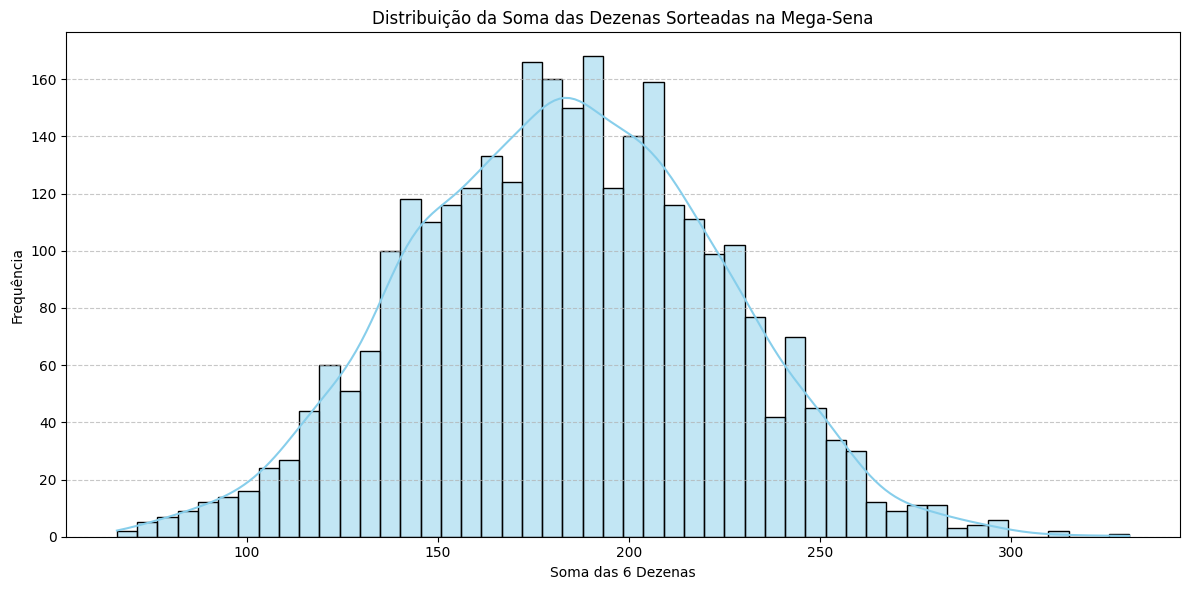

In [93]:
import pandas as pd

# As colunas das dezenas já estão definidas como 'colunas_bolas'
# Se não estiverem, descomente a linha abaixo:
# colunas_bolas = ['Bola1', 'Bola2', 'Bola3', 'Bola4', 'Bola5', 'Bola6']

# Função para calcular a soma ponderada das dezenas de um sorteio
def calcular_soma_ponderada_dezenas(row, pesos=None):
    if pesos is None: # Se nenhum peso for fornecido, todos os pesos são 1 (soma simples)
        pesos = [1] * len(colunas_bolas)

    soma_ponderada = 0
    for i, col in enumerate(colunas_bolas):
        soma_ponderada += row[col] * pesos[i]
    return soma_ponderada

# Aplica a função ao DataFrame df_mega_sena para criar a nova coluna 'Soma_Das_Dezenas'
# Usando pesos padrão (todos 1) para a soma simples
print("Calculando a soma das dezenas para cada sorteio...")
df_mega_sena['Soma_Das_Dezenas'] = df_mega_sena.apply(calcular_soma_ponderada_dezenas, axis=1)

print("Exibindo os primeiros resultados com a nova coluna:")
display(df_mega_sena[['Concurso', 'Data do Sorteio'] + colunas_bolas + ['Soma_Das_Dezenas']].head())

# Podemos também visualizar a distribuição dessas somas
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.histplot(df_mega_sena['Soma_Das_Dezenas'], bins=50, kde=True, color='skyblue')
plt.title('Distribuição da Soma das Dezenas Sorteadas na Mega-Sena')
plt.xlabel('Soma das 6 Dezenas')
plt.ylabel('Frequência')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [94]:
most_frequent_sum = df_mega_sena['Soma_Das_Dezenas'].mode()[0]
print(f"A soma das dezenas mais frequente encontrada nos sorteios é: {most_frequent_sum}")

A soma das dezenas mais frequente encontrada nos sorteios é: 182


A distribuição da soma das dezenas mostra que a maioria dos sorteios tende a ter uma soma entre 120 e 200, com menos ocorrências em extremos muito baixos ou muito altos. Isso é esperado, pois é menos provável sortear apenas números muito baixos (ex: 1,2,3,4,5,6 = soma 21) ou apenas números muito altos (ex: 55,56,57,58,59,60 = soma 345).

Se você tiver interesse em explorar pesos diferentes para as dezenas (ex: dar mais peso às dezenas maiores ou menores, ou pesos baseados em outras estatísticas), por favor me diga! Podemos ajustar a função `calcular_soma_ponderada_dezenas` para aceitar um array de pesos personalizado.

In [95]:
print("Calculando a soma das dezenas com pesos personalizados (dezenas maiores têm mais peso)...")

# Definir pesos personalizados (exemplo: dar mais peso às últimas dezenas)
pesos_personalizados_crescente = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75]

df_mega_sena['Soma_Ponderada_Crescente'] = df_mega_sena.apply(lambda row: calcular_soma_ponderada_dezenas(row, pesos=pesos_personalizados_crescente), axis=1)

print("Exibindo os primeiros resultados com a nova coluna de soma ponderada crescente:")
display(df_mega_sena[['Concurso', 'Data do Sorteio'] + colunas_bolas + ['Soma_Ponderada_Crescente']].head())

Calculando a soma das dezenas com pesos personalizados (dezenas maiores têm mais peso)...
Exibindo os primeiros resultados com a nova coluna de soma ponderada crescente:


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6,Soma_Ponderada_Crescente
0,1,11/03/1996,4,5,30,33,41,52,229.50
1,2,18/03/1996,9,37,39,41,43,49,272.75
2,3,25/03/1996,10,11,29,30,36,47,216.00
3,4,01/04/1996,1,5,6,27,42,59,210.25
4,5,08/04/1996,1,2,6,16,19,46,137.00


In [96]:
print("Calculando a soma das dezenas com pesos personalizados (dezenas menores têm mais peso)...")

# Definir pesos personalizados (exemplo: dar mais peso às primeiras dezenas)
pesos_personalizados_decrescente = [1.75, 1.5, 1.25, 1.0, 0.75, 0.5]

df_mega_sena['Soma_Ponderada_Decrescente'] = df_mega_sena.apply(lambda row: calcular_soma_ponderada_dezenas(row, pesos=pesos_personalizados_decrescente), axis=1)

print("Exibindo os primeiros resultados com a nova coluna de soma ponderada decrescente:")
display(df_mega_sena[['Concurso', 'Data do Sorteio'] + colunas_bolas + ['Soma_Ponderada_Decrescente']].head())

Calculando a soma das dezenas com pesos personalizados (dezenas menores têm mais peso)...
Exibindo os primeiros resultados com a nova coluna de soma ponderada decrescente:


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Bola5,Bola6,Soma_Ponderada_Decrescente
0,1,11/03/1996,4,5,30,33,41,52,141.75
1,2,18/03/1996,9,37,39,41,43,49,217.75
2,3,25/03/1996,10,11,29,30,36,47,150.75
3,4,01/04/1996,1,5,6,27,42,59,104.75
4,5,08/04/1996,1,2,6,16,19,46,65.50


### Cálculo do "Determinante" de uma Submatriz 2x2 (Bolas 1-4)

Conforme solicitado, vamos calcular um valor que o usuário chamou de "determinante" para cada sorteio, usando as dezenas 'Bola1', 'Bola2', 'Bola3' e 'Bola4'.

Assumiremos que a submatriz 2x2 é formada da seguinte maneira:

```
| Bola1  Bola2 |
| Bola3  Bola4 |
```

E o "determinante" será calculado como: `(Bola1 * Bola4) - (Bola2 * Bola3)`.

Calculando o 'determinante' para cada sorteio...
Exibindo os primeiros resultados com a nova coluna 'Determinante_Bola1_4':


,Concurso,Data do Sorteio,Bola1,Bola2,Bola3,Bola4,Determinante_Bola1_4
0,1,11/03/1996,4,5,30,33,-18
1,2,18/03/1996,9,37,39,41,-1074
2,3,25/03/1996,10,11,29,30,-19
3,4,01/04/1996,1,5,6,27,-3
4,5,08/04/1996,1,2,6,16,4


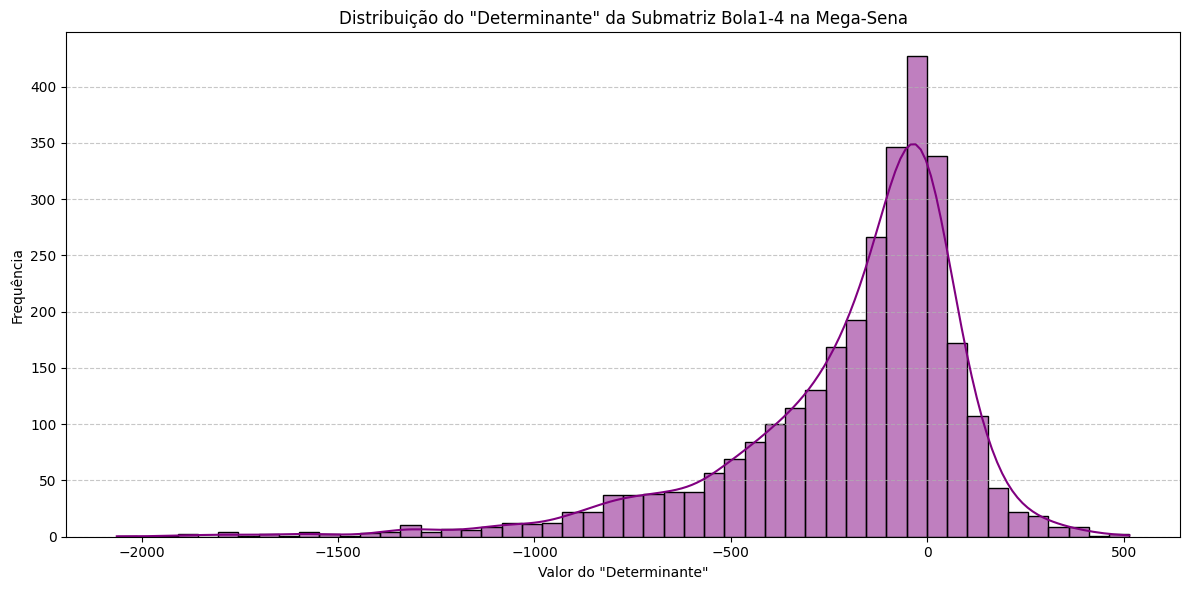

Estatísticas descritivas para a coluna 'Determinante_Bola1_4':


,Determinante_Bola1_4
count,3009.000000
mean,-197.993021
std,308.829604
min,-2063.000000
25%,-313.000000
50%,-106.000000
75%,-5.000000
max,514.000000


In [97]:
import numpy as np

def calcular_determinante_bola1_4(row):
    """Calcula o "determinante" de uma submatriz 2x2 usando Bola1, Bola2, Bola3 e Bola4."""
    bola1 = row['Bola1']
    bola2 = row['Bola2']
    bola3 = row['Bola3']
    bola4 = row['Bola4']

    # Determinante de [[a, b], [c, d]] é (a*d) - (b*c)
    determinante = (bola1 * bola4) - (bola2 * bola3)
    return determinante

print("Calculando o 'determinante' para cada sorteio...")
df_mega_sena['Determinante_Bola1_4'] = df_mega_sena.apply(calcular_determinante_bola1_4, axis=1)

print("Exibindo os primeiros resultados com a nova coluna 'Determinante_Bola1_4':")
display(df_mega_sena[['Concurso', 'Data do Sorteio', 'Bola1', 'Bola2', 'Bola3', 'Bola4', 'Determinante_Bola1_4']].head())

# Visualizar a distribuição dos determinantes
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.histplot(df_mega_sena['Determinante_Bola1_4'], bins=50, kde=True, color='purple')
plt.title('Distribuição do "Determinante" da Submatriz Bola1-4 na Mega-Sena')
plt.xlabel('Valor do "Determinante"')
plt.ylabel('Frequência')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("Estatísticas descritivas para a coluna 'Determinante_Bola1_4':")
display(df_mega_sena['Determinante_Bola1_4'].describe())

Entendo sua pergunta sobre a probabilidade de sorteios com números em sequência. É uma curiosidade comum! Vamos analisar isso com a matemática da Mega-Sena.

A Mega-Sena sorteia 6 números de um universo de 60. O número total de combinações possíveis é `comb(60, 6)`, que é **50.063.860**.

### Probabilidade de uma Sequência Específica (ex: 1-2-3-4-5-6)

Para qualquer sequência específica de 6 números (como `[1, 2, 3, 4, 5, 6]`), a probabilidade de ela ser sorteada é de **1 em 50.063.860**. É a mesma probabilidade de qualquer outra combinação, por mais 'aleatória' que pareça (ex: `[7, 18, 23, 34, 45, 59]`). Cada combinação tem a mesma chance de ocorrer.

### Probabilidade de *Qualquer* Sequência de 6 Números Consecutivos

Agora, se a pergunta é sobre a probabilidade de **qualquer** sorteio ter 6 números consecutivos (não uma sequência específica, mas *alguma* sequência), o cálculo muda:

*   **Quantas sequências de 6 números consecutivos existem?**
    *   `[1, 2, 3, 4, 5, 6]`
    *   `[2, 3, 4, 5, 6, 7]`
    *   ...
    *   `[55, 56, 57, 58, 59, 60]`

    Existem `(60 - 6 + 1) = 55` sequências possíveis de 6 números consecutivos.

*   **Probabilidade:** A probabilidade de o sorteio ser uma dessas 55 sequências é de `55 / 50.063.860`, que é aproximadamente **1 em 910.252**.

### Seu Exemplo: 50-51-52-52-54-55-56

Seu segundo exemplo `50-51-52-52-54-55-56` contém um erro, pois há 7 números e o `52` se repete. A Mega-Sena sorteia 6 números distintos. Se ajustarmos para 6 números distintos em sequência, a lógica acima se aplica.

---

In [99]:
from math import comb

# Parâmetros da Mega-Sena
num_total_bolas = 60  # De 1 a 60
num_bolas_sorteadas = 6

# 1. Calcular o número total de combinações possíveis (comb(60, 6))
total_combinacoes = comb(num_total_bolas, num_bolas_sorteadas)
print(f"Número total de combinações possíveis na Mega-Sena: {total_combinacoes:,}")

# 2. Calcular a probabilidade de uma sequência ESPECÍFICA (ex: 1-2-3-4-5-6)
# Cada combinação tem a mesma probabilidade
prob_especifica_consecutiva = 1 / total_combinacoes
print(f"Probabilidade de uma sequência específica de 6 números (ex: [1,2,3,4,5,6]) ser sorteada: 1 em {total_combinacoes:,} ({prob_especifica_consecutiva:.15f})")

# 3. Calcular o número de sequências de 6 números consecutivos existentes
# Ex: [1,2,3,4,5,6], [2,3,4,5,6,7], ..., [55,56,57,58,59,60]
num_sequencias_consecutivas = num_total_bolas - num_bolas_sorteadas + 1
print(f"Número de sequências de 6 números consecutivos possíveis: {num_sequencias_consecutivas}")

# 4. Calcular a probabilidade de QUALQUER sequência de 6 números consecutivos
prob_qualquer_consecutiva = num_sequencias_consecutivas / total_combinacoes
print(f"Probabilidade de QUALQUER sequência de 6 números consecutivos ser sorteada: {num_sequencias_consecutivas} em {total_combinacoes:,} ({prob_qualquer_consecutiva:.15f})")
print(f"Isso é aproximadamente 1 em {1/prob_qualquer_consecutiva:,.0f}")

Número total de combinações possíveis na Mega-Sena: 50,063,860
Probabilidade de uma sequência específica de 6 números (ex: [1,2,3,4,5,6]) ser sorteada: 1 em 50,063,860 (0.000000019974489)
Número de sequências de 6 números consecutivos possíveis: 55
Probabilidade de QUALQUER sequência de 6 números consecutivos ser sorteada: 55 em 50,063,860 (0.000001098596872)
Isso é aproximadamente 1 em 910,252


### Probabilidade de *Qualquer* Sequência de 5 Números Consecutivos

Agora vamos calcular as probabilidades para 5 números consecutivos.

In [101]:
from math import comb

# Parâmetros da Mega-Sena (contexto de um sorteio de 6 dezenas)
num_total_bolas_mega = 60  # De 1 a 60
num_bolas_sorteadas_mega = 6 # Um sorteio da Mega-Sena tem 6 dezenas

# 1. Calcular o número total de combinações possíveis (comb(60, 6))
total_combinacoes_mega = comb(num_total_bolas_mega, num_bolas_sorteadas_mega)
print(f"Número total de combinações possíveis na Mega-Sena: {total_combinacoes_mega:,}")

# 2. Número de sequências de 5 números consecutivos existentes
# Ex: [1,2,3,4,5], [2,3,4,5,6], ..., [56,57,58,59,60]
num_blocos_5_consecutivos = num_total_bolas_mega - 5 + 1 # 56 blocos de 5 consecutivos
print(f"Número de blocos de 5 números consecutivos possíveis: {num_blocos_5_consecutivos}")

# 3. Número de sequências de 6 números consecutivos existentes
# Ex: [1,2,3,4,5,6], [2,3,4,5,6,7], ..., [55,56,57,58,59,60]
num_sequencias_6_consecutivas = num_total_bolas_mega - num_bolas_sorteadas_mega + 1 # 55 sequências de 6
print(f"Número de sequências de 6 números consecutivos possíveis: {num_sequencias_6_consecutivas}")

# 4. Calcular o número de combinações de 6 dezenas que contêm EXATAMENTE 5 números consecutivos
# e o sexto número NÃO é adjacente para formar uma sequência de 6.

# Casos de borda: O bloco de 5 começa em 1 (1,2,3,4,5) ou termina em 60 (56,57,58,59,60)
# Para (1,2,3,4,5), o 6º número não pode ser 6. Restam (60 - 5 - 1) = 54 escolhas.
# Para (56,57,58,59,60), o 6º número não pode ser 55. Restam (60 - 5 - 1) = 54 escolhas.
num_combinacoes_borda = 2 * (num_total_bolas_mega - 5 - 1)

# Casos do meio: O bloco de 5 não está nas bordas (ex: 2,3,4,5,6 a 55,56,57,58,59)
# Existem (num_blocos_5_consecutivos - 2) blocos do meio (56 - 2 = 54 blocos).
# Para cada um, o 6º número não pode ser o anterior (s-1) nem o posterior (s+5).
# Restam (60 - 5 - 2) = 53 escolhas.
num_combinacoes_meio = (num_blocos_5_consecutivos - 2) * (num_total_bolas_mega - 5 - 2)

num_combinacoes_exatamente_5_consecutivas = num_combinacoes_borda + num_combinacoes_meio

print(f"Número de combinações com exatamente 5 números consecutivos (e o 6º não adjacente): {num_combinacoes_exatamente_5_consecutivas}")

# 5. Calcular o número total de combinações com PELO MENOS 5 números consecutivos
# = (Combinações com exatamente 6 consecutivos) + (Combinações com exatamente 5 consecutivos e 1 não adjacente)
total_combinacoes_pelo_menos_5_consecutivas = num_sequencias_6_consecutivas + num_combinacoes_exatamente_5_consecutivas
print(f"Número total de combinações com pelo menos 5 números consecutivos: {total_combinacoes_pelo_menos_5_consecutivas}")

# 6. Calcular a probabilidade
probabilidade_pelo_menos_5_consecutivas = total_combinacoes_pelo_menos_5_consecutivas / total_combinacoes_mega

print(f"Probabilidade de um sorteio da Mega-Sena ter pelo menos 5 números consecutivos: {total_combinacoes_pelo_menos_5_consecutivas} em {total_combinacoes_mega:,} ({probabilidade_pelo_menos_5_consecutivas:.15f})")
print(f"Isso é aproximadamente 1 em {1/probabilidade_pelo_menos_5_consecutivas:,.0f}")

Número total de combinações possíveis na Mega-Sena: 50,063,860
Número de blocos de 5 números consecutivos possíveis: 56
Número de sequências de 6 números consecutivos possíveis: 55
Número de combinações com exatamente 5 números consecutivos (e o 6º não adjacente): 2970
Número total de combinações com pelo menos 5 números consecutivos: 3025
Probabilidade de um sorteio da Mega-Sena ter pelo menos 5 números consecutivos: 3025 em 50,063,860 (0.000060422827964)
Isso é aproximadamente 1 em 16,550


In [ ]:
import numpy as np
import pandas as pd
from math import comb

# Certifique-se de que `window_size`, `scaler`, `model` e `df_mega_sena`
# foram definidos e carregados de células anteriores.
# Para garantir, vou redefinir a função indice_para_combinacao aqui, caso a célula original não tenha sido executada.

def indice_para_combinacao(index, n=60, k=6):
    """Converte um índice (1-50.063.860) de volta para os 6 números"""
    combinacao = []
    current = 1
    for i in range(k):
        while True:
            c = comb(n - current, k - 1 - i)
            if index <= c:
                combinacao.append(current)
                break
            index -= c
            current += 1
        current += 1
    return combinacao

# 1. Pegar os últimos 'window_size' concursos do DataFrame original
# Assumindo window_size = 10, conforme definido na célula de treinamento da LSTM (BOX62o1L2lLT)
# Se window_size não estiver definido, use 10 como fallback

if 'window_size' not in locals():
    window_size = 10

ultimos_10_indices = df_mega_sena['Indice_Combinacao'].tail(window_size).values.reshape(-1, 1)

# 2. Normalizar esses dados com o mesmo scaler usado no treino
# `scaler` e `model` são definidos na célula BOX62o1L2lLT.
ultimos_10_norm = scaler.transform(ultimos_10_indices)

# 3. Preparar o formato para a Rede Neural (1 amostra, 10 janelas, 1 recurso)
entrada_predict = np.reshape(ultimos_10_norm, (1, window_size, 1))

# 4. Realizar a Previsão
predicao_norm = model.predict(entrada_predict)

# 5. Desnormalizar para obter o Índice de 1 a 50M
indice_previsto = int(scaler.inverse_transform(predicao_norm)[0][0])

# 6. Resultado Final
jogo_previsto = indice_para_combinacao(indice_previsto)

print("-" * 40)
print(f"PREVISÃO DA REDE LSTM PARA O PRÓXIMO CONCURSO ({df_mega_sena['Concurso'].max() + 1})")
print(f"Índice Previsto pela Rede: {indice_previsto:,}")
print(f"Números Sugeridos: {jogo_previsto}")
print("-" * 40)

Você pode ajustar a lista `pesos` conforme sua preferência, passando 6 valores correspondentes às `Bola1` a `Bola6`.